<a href="https://colab.research.google.com/github/harisankar-work/Amlbt/blob/main/B2026127_Session_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Dataset Overview

First, we will load the dataset, check its shape, inspect raw data columns, data types, and check for missing values and duplicates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset
filepath = '/content/bengaluru_house_prices.csv'
df = pd.read_csv(filepath)

print("Dataset Shape:", df.shape)
print("\n--- Dataset Columns & Types ---")
display(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

Dataset Shape: (13320, 9)

--- Dataset Columns & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


None


--- First 5 Rows ---


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00



--- Summary Statistics ---


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
count,13320,13320,13319,13304,7818,13320,13247.000000,12711.000000,13320.000000
unique,4,81,1305,31,2688,2117,NaN,NaN,NaN
top,Super built-up Area,Ready To Move,Whitefield,2 BHK,GrrvaGr,1200,NaN,NaN,NaN
freq,8790,10581,540,5199,80,843,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.692610,1.584376,112.565627
std,NaN,NaN,NaN,NaN,NaN,NaN,1.341458,0.817263,148.971674
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,8.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,50.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,72.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,120.000000


In [2]:
# Identify missing values (%), duplicates, and unique values per column
missing_percent = (df.isnull().sum() / len(df)) * 100
unique_counts = df.nunique()

overview_df = pd.DataFrame({
    'Missing (%)': missing_percent,
    'Unique Values': unique_counts,
    'Data Type': df.dtypes
})
print("--- Missing Values and Cardinality ---")
display(overview_df)

print(f"\nDuplicate rows count: {df.duplicated().sum()}")

--- Missing Values and Cardinality ---


,Missing (%),Unique Values,Data Type
area_type,0.000000,4,object
availability,0.000000,81,object
location,0.007508,1305,object
size,0.120120,31,object
society,41.306306,2688,object
total_sqft,0.000000,2117,object
bath,0.548048,19,float64
balcony,4.572072,4,float64
price,0.000000,1994,float64



Duplicate rows count: 529


# 2. Data Cleaning

We will now:
1. Extract BHK numeric values from the `size` column.
2. Convert the `total_sqft` column (handling ranges like '2100 - 2850' or values with units like 'Perch', 'Sq. Yards', etc.) to numeric square footage.
3. Impute or handle missing values appropriately.
4. Clean and standardize features such as `bath`, `balcony`, `area_type`, and `location`.
5. Save the cleaned dataset as `bengaluru_house_prices_cleaned.csv`.

In [3]:
# Clean size column and extract BHK
def extract_bhk(x):
    if pd.isna(x):
        return np.nan
    tokens = str(x).split(' ')
    try:
        return float(tokens[0])
    except:
        return np.nan

df['bhk'] = df['size'].apply(extract_bhk)

# Convert total_sqft to numeric
def convert_sqft_to_num(x):
    if pd.isna(x):
        return np.nan
    x_str = str(x).strip()
    # Handle ranges
    if '-' in x_str:
        tokens = x_str.split('-')
        try:
            return (float(tokens[0].strip()) + float(tokens[1].strip())) / 2
        except:
            return np.nan
    # Handle alphanumeric values / unit conversions roughly or return NaN
    try:
        return float(x_str)
    except:
        # Look for common units and convert roughly if possible
        import re
        val = re.findall(r'\d+\.?\d*', x_str)
        if not val:
            return np.nan
        num = float(val[0])
        if 'Sq. Yards' in x_str:
            return num * 9
        elif 'Sq. Meter' in x_str:
            return num * 10.7639
        elif 'Acres' in x_str:
            return num * 43560
        elif 'Cent' in x_str:
            return num * 435.56
        elif 'Guntha' in x_str:
            return num * 1089
        elif 'Grounds' in x_str:
            return num * 2400
        elif 'Perch' in x_str:
            return num * 272.25
        return np.nan

df['total_sqft_cleaned'] = df['total_sqft'].apply(convert_sqft_to_num)

# Drop rows where critical variables (price, total_sqft_cleaned) are null or extremely corrupt
df_cleaned = df.dropna(subset=['price', 'total_sqft_cleaned']).copy()

# Handle missing values for categorical and numerical features
# Location: impute with mode or 'Unknown'
df_cleaned['location'] = df_cleaned['location'].fillna('Unknown').apply(lambda x: x.strip())

# BHK and Bath: Impute with median based on typical relationships
df_cleaned['bhk'] = df_cleaned.groupby('location')['bhk'].transform(lambda x: x.fillna(x.median() if not x.dropna().empty else 2))
df_cleaned['bath'] = df_cleaned.groupby('bhk')['bath'].transform(lambda x: x.fillna(x.median() if not x.dropna().empty else x.name))
df_cleaned['balcony'] = df_cleaned.groupby('bhk')['balcony'].transform(lambda x: x.fillna(x.median() if not x.dropna().empty else 1))

# Ensure final integer representations where appropriate
df_cleaned['bhk'] = df_cleaned['bhk'].fillna(2).astype(int)
df_cleaned['bath'] = df_cleaned['bath'].fillna(df_cleaned['bhk']).astype(int)
df_cleaned['balcony'] = df_cleaned['balcony'].fillna(1).astype(int)

# Remove duplicate rows
df_cleaned = df_cleaned.drop_duplicates()

# Save the cleaned dataset
df_cleaned.to_csv('/content/bengaluru_house_prices_cleaned.csv', index=False)
print("Cleaned Dataset Shape:", df_cleaned.shape)
display(df_cleaned.head())

Cleaned Dataset Shape: (12789, 11)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk,total_sqft_cleaned
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2,1,39.07,2,1056.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5,3,120.00,4,2600.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2,3,62.00,3,1440.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3,1,95.00,3,1521.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2,1,51.00,2,1200.0


# 3. Univariate Analysis

Let's analyze numerical and categorical features individually.

/tmp/ipykernel_3257/3014487539.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, x='bhk', ax=axes[1, 0], palette='viridis')
/tmp/ipykernel_3257/3014487539.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, x='bath', ax=axes[1, 1], palette='magma')


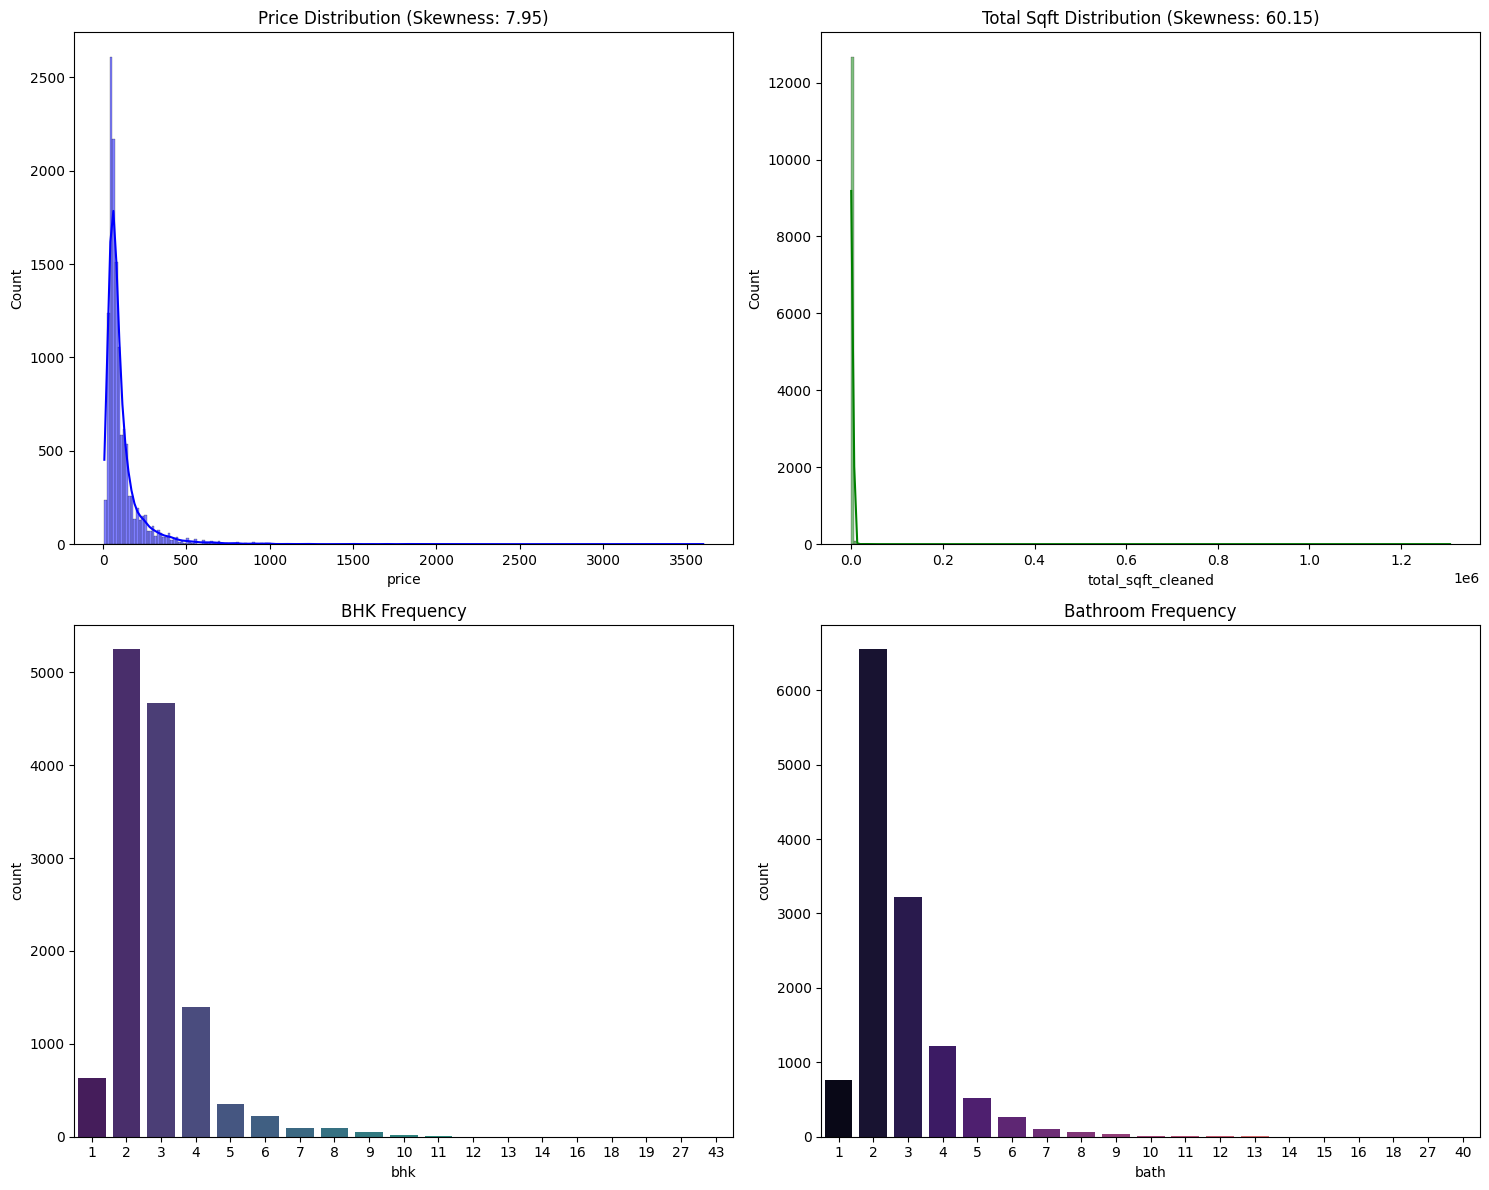

In [4]:
# Distributions of Numerical Features
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
sns.histplot(df_cleaned['price'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title(f"Price Distribution (Skewness: {df_cleaned['price'].skew():.2f})")

sns.histplot(df_cleaned['total_sqft_cleaned'], kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title(f"Total Sqft Distribution (Skewness: {df_cleaned['total_sqft_cleaned'].skew():.2f})")

sns.countplot(data=df_cleaned, x='bhk', ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title("BHK Frequency")

sns.countplot(data=df_cleaned, x='bath', ax=axes[1, 1], palette='magma')
axes[1, 1].set_title("Bathroom Frequency")

plt.tight_layout()
plt.show()

# 4. Bivariate, Multivariate, and Statistical Analysis

Now, let's explore relationships between features, correlations, identify outliers, do some feature engineering (creating price per sqft for EDA), and finalize the statistical insights.

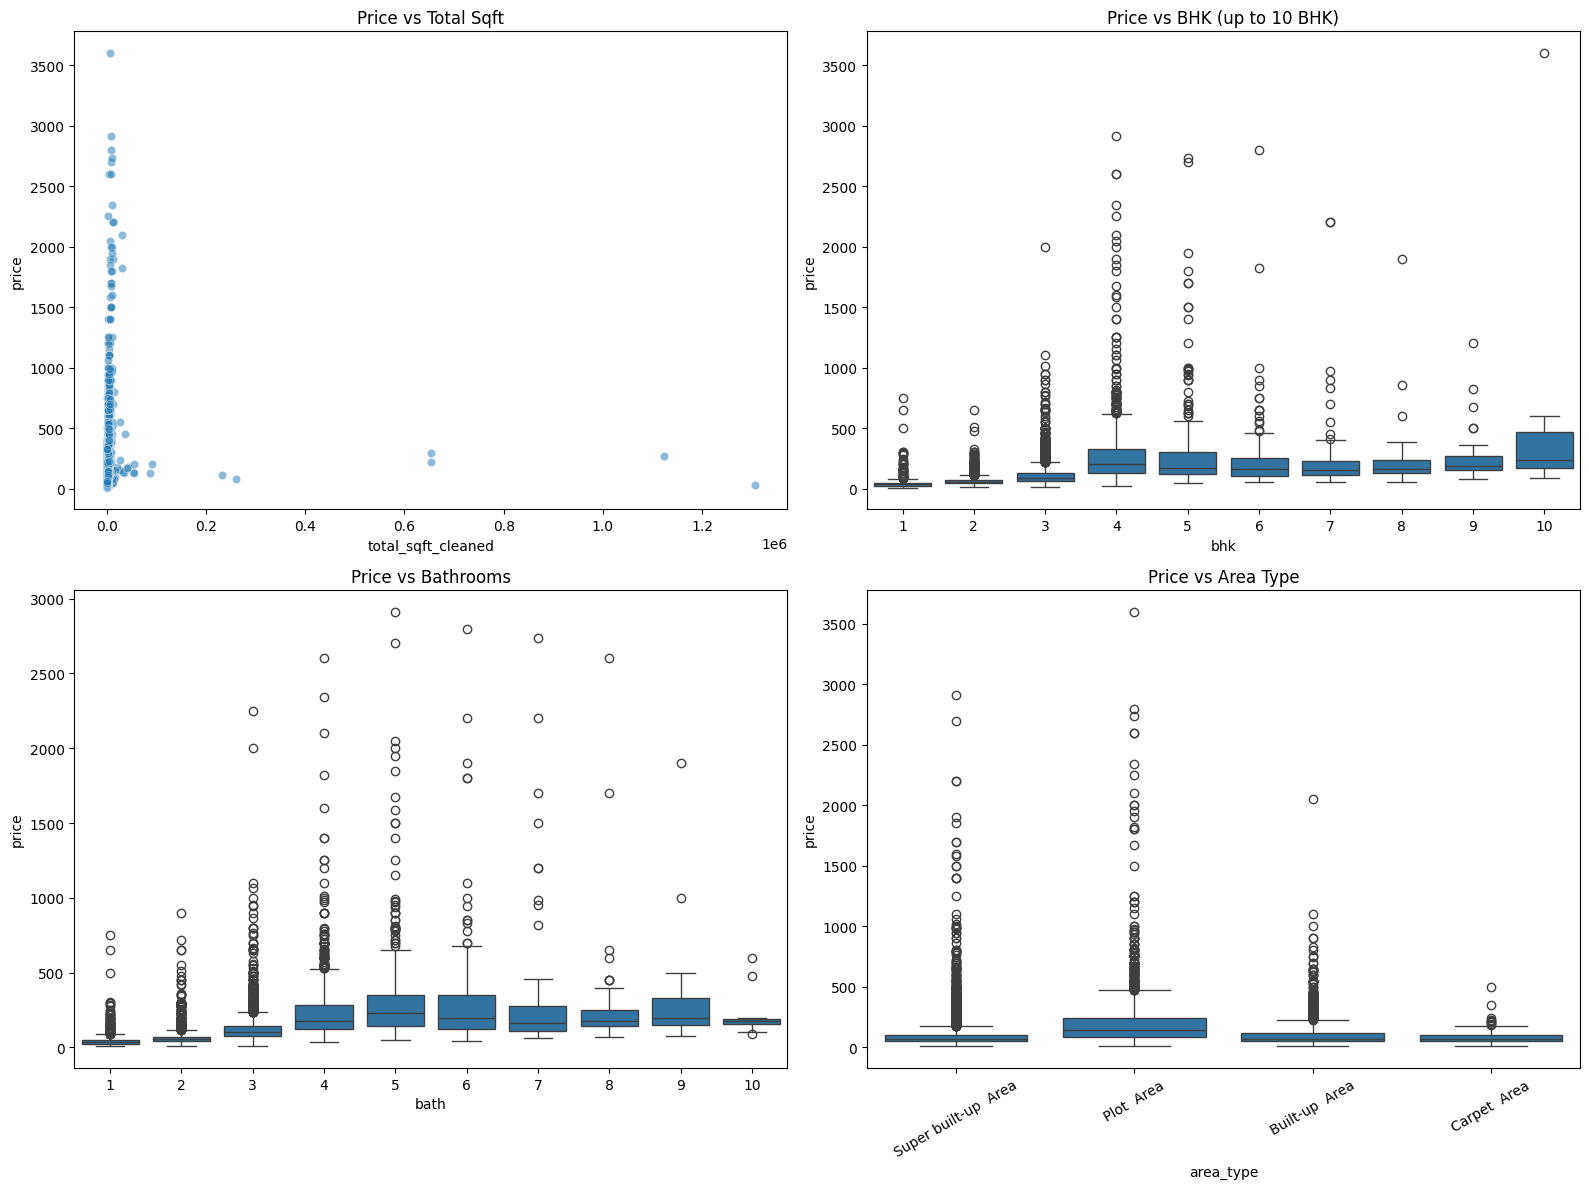

In [5]:
# 4. Bivariate Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Price vs Sqft
sns.scatterplot(data=df_cleaned, x='total_sqft_cleaned', y='price', ax=axes[0, 0], alpha=0.5)
axes[0, 0].set_title('Price vs Total Sqft')

# Price vs BHK
sns.boxplot(data=df_cleaned[df_cleaned['bhk'] <= 10], x='bhk', y='price', ax=axes[0, 1])
axes[0, 1].set_title('Price vs BHK (up to 10 BHK)')

# Price vs Bath
sns.boxplot(data=df_cleaned[df_cleaned['bath'] <= 10], x='bath', y='price', ax=axes[1, 0])
axes[1, 0].set_title('Price vs Bathrooms')

# Price vs Area Type
sns.boxplot(data=df_cleaned, x='area_type', y='price', ax=axes[1, 1])
axes[1, 1].set_title('Price vs Area Type')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

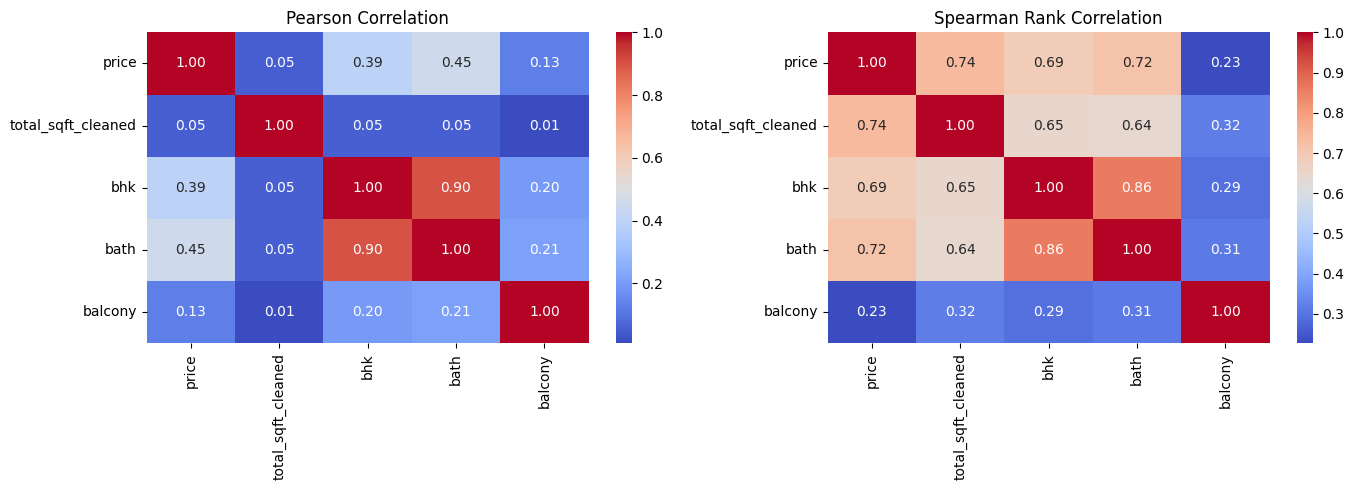

In [6]:
# 5. & 6. Multivariate & Statistical Analysis
# Pearson / Spearman correlation
corr_cols = ['price', 'total_sqft_cleaned', 'bhk', 'bath', 'balcony']
pearson_corr = df_cleaned[corr_cols].corr(method='pearson')
spearman_corr = df_cleaned[corr_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Pearson Correlation')

sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Spearman Rank Correlation')

plt.tight_layout()
plt.show()

In [7]:
# 7. Feature Engineering (EDA-only metrics to avoid leakages)
# We'll calculate price per sqft for outlier analysis / visualization only.
df_cleaned['price_per_sqft'] = (df_cleaned['price'] * 100000) / df_cleaned['total_sqft_cleaned']

# Rare Location handling: Group locations with fewer than 10 properties as 'Other'
location_stats = df_cleaned['location'].value_counts(ascending=False)
locations_less_than_10 = location_stats[location_stats <= 10]
df_cleaned['location_cleaned'] = df_cleaned['location'].apply(lambda x: 'other' if x in locations_less_than_10 else x)

print(f"Original locations: {df_cleaned['location'].nunique()}")
print(f"Grouped locations (>=10 samples): {df_cleaned['location_cleaned'].nunique()}")

# Display summary details of cleaning and features
display(df_cleaned.describe())

Original locations: 1295
Grouped locations (>=10 samples): 234


,bath,balcony,price,bhk,total_sqft_cleaned,price_per_sqft
count,12789.000000,12789.00000,12789.000000,12789.000000,1.278900e+04,1.278900e+04
mean,2.711158,1.59817,114.328878,2.817969,1.936256e+03,8.017339e+03
std,1.356152,0.80941,151.489369,1.311096,1.763113e+04,1.084301e+05
min,1.000000,0.00000,8.000000,1.000000,1.000000e+00,2.257423e+00
25%,2.000000,1.00000,50.000000,2.000000,1.100000e+03,4.292683e+03
50%,2.000000,2.00000,73.000000,3.000000,1.282000e+03,5.479452e+03
75%,3.000000,2.00000,121.000000,3.000000,1.694000e+03,7.399577e+03
max,40.000000,3.00000,3600.000000,43.000000,1.306800e+06,1.200000e+07


# Part 1: Data Preprocessing

To prepare our data for the Artificial Neural Network, we must follow these steps:
1. **Separate Features and Target**: The target is `price` (in Lakhs).
2. **Avoid Data Leakage**: We drop the feature `price_per_sqft` since it is derived from our target and would cause severe data leakage.
3. **Encode Categorical Features**: We will use One-Hot Encoding on categorical features: `area_type` and `location_cleaned`.
4. **Scale Numerical Features**: Numerical features (`total_sqft_cleaned`, `bhk`, `bath`, `balcony`) must be scaled.
5. **Train-Test Split**: We split the dataset into an 80% training set and a 20% test set.

### Why Scaling is Important for Neural Networks:
- **Gradient Descent Convergence**: Features on vastly different scales (e.g., square feet in thousands vs. number of bathrooms as single digits) lead to highly elongated, asymmetrical loss landscapes. This causes gradient descent to oscillate inefficiently, slowing down or preventing convergence.
- **Weight Initialization & Activation Functions**: Saturated activation functions like Sigmoid or Tanh, and even unbounded ones like ReLU, can behave poorly if extreme input values cause vanishing/exploding gradients. Scaling ensures values stay within stable, active regimes.

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import joblib

# Load the cleaned dataset
df_clean = pd.read_csv('/content/bengaluru_house_prices_cleaned.csv')

# Re-apply the location cleaning transformation to ensure consistency
location_stats = df_clean['location'].value_counts(ascending=False)
locations_less_than_10 = location_stats[location_stats <= 10]
df_clean['location_cleaned'] = df_clean['location'].apply(lambda x: 'other' if x in locations_less_than_10 else x)

# Define the target variable
y = df_clean['price']

# Exclude target-derived features and non-predictive features safely using errors='ignore'
X = df_clean.drop(columns=['price', 'price_per_sqft', 'location', 'size', 'society', 'availability'], errors='ignore')

# Define feature groups
num_features = ['total_sqft_cleaned', 'bhk', 'bath', 'balcony']
cat_features = ['area_type', 'location_cleaned']

# Split into 80% Train and 20% Test (Validation is carved out during training)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create a preprocessing column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

# Fit preprocessor on training data and transform both train and test
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Save preprocessor for later use
joblib.dump(preprocessor, '/content/preprocessor.joblib')

print("Preprocessed Training shape:", X_train_preprocessed.shape)
print("Preprocessed Test shape:", X_test_preprocessed.shape)

Preprocessed Training shape: (10231, 242)
Preprocessed Test shape: (2558, 242)


# Part 2: ANN Architecture

We build a baseline Feedforward Deep Neural Network (Sequential API) with the specified layers and hidden units. The final dense layer has a single output unit with a linear activation function for continuous numerical prediction (regression).

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Define Model Architecture
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_preprocessed.shape[1],), name='Input_Hidden1'),
    Dense(64, activation='relu', name='Hidden2'),
    Dense(32, activation='relu', name='Hidden3'),
    Dense(1, activation='linear', name='Output')
])

# 2. Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Display summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Hidden1 (Dense)           │ (None, 128)            │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,473 (162.00 KB)

 Trainable params: 41,473 (162.00 KB)

 Non-trainable params: 0 (0.00 B)

# Part 5: ANN Training (Baseline Model)

We train our baseline ANN using:
- **epochs = 200** with a **batch_size = 32**.
- **EarlyStopping**: Patience of 15 epochs monitoring validation loss, restoring the best model weights.
- **ReduceLROnPlateau**: Automatically reduces the learning rate when the validation loss halts improvement.
- **ModelCheckpoint**: Saves the best version of the model to a `.keras` format.

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import os

# Define callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='/content/best_baseline_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

# Train baseline model
history = model.fit(
    X_train_preprocessed, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 21647.2559 - mae: 69.0756 - val_loss: 14963.2344 - val_mae: 52.2661 - learning_rate: 0.0010
Epoch 2/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 19600.3652 - mae: 53.0633 - val_loss: 14883.2402 - val_mae: 52.3391 - learning_rate: 0.0010
Epoch 3/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 17881.9805 - mae: 52.3883 - val_loss: 14854.4131 - val_mae: 52.3111 - learning_rate: 0.0010
Epoch 4/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 17070.9453 - mae: 51.8595 - val_loss: 14776.6914 - val_mae: 51.8538 - learning_rate: 0.0010
Epoch 5/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 16491.6328 - mae: 50.9112 - val_loss: 14557.3877 - val_mae: 50.8742 - learning_rate: 0.0010
Epoch 6/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15915.1514 - mae: 49.9739 - val_loss: 14269.6729 - val_mae: 49.7727 - learning_rate: 0.0010
Epoch 7/200
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15392.9541 - mae: 49.

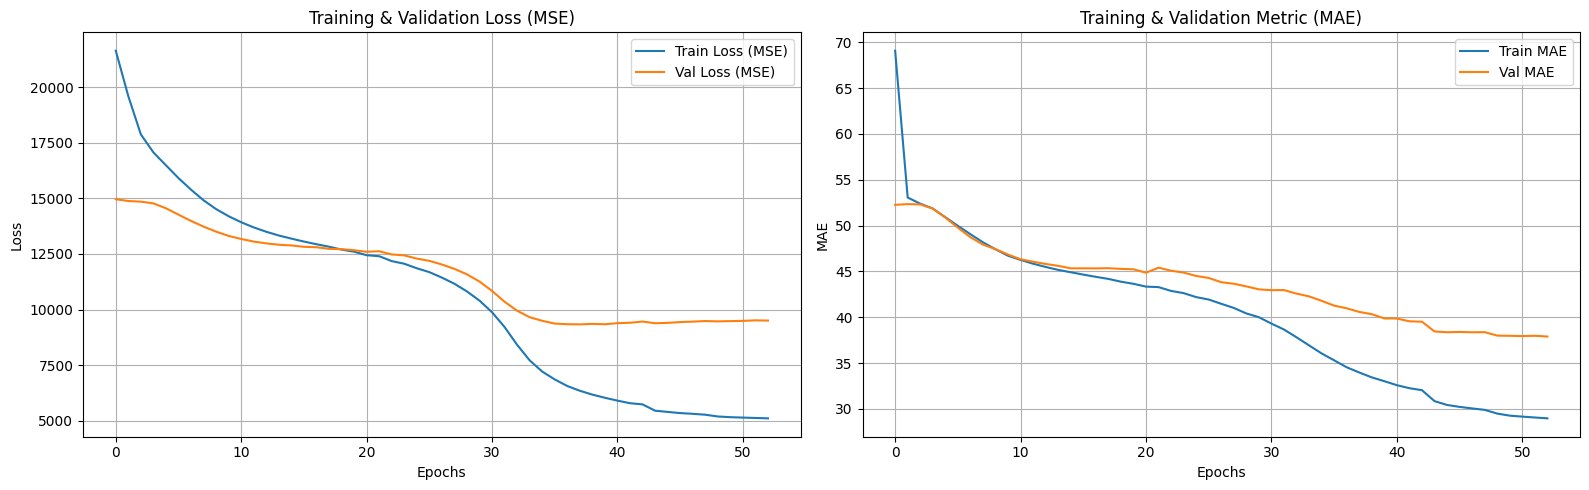

In [12]:
# Plot Training vs Validation Curves
hist_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss Curve
axes[0].plot(hist_df['loss'], label='Train Loss (MSE)')
axes[0].plot(hist_df['val_loss'], label='Val Loss (MSE)')
axes[0].set_title('Training & Validation Loss (MSE)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# MAE Curve
axes[1].plot(hist_df['mae'], label='Train MAE')
axes[1].plot(hist_df['val_mae'], label='Val MAE')
axes[1].set_title('Training & Validation Metric (MAE)')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Understanding Epochs, Batches, and Iterations

To understand how neural networks learn, we must clarify how the training data is consumed. In our baseline ANN model, we set the maximum training duration to **200 epochs** with a **batch size of 32**.

*   **Epoch**: One complete pass of the entire training dataset through the neural network (both forward and backward).
*   **Batch Size**: The subset of training samples processed by the network before updating the internal model parameters (weights and biases). Rather than calculating gradients for all 10,231 training samples at once (which is memory-heavy) or updating after every single sample (which is highly unstable), we group them into batches of 32.
*   **Iteration**: The completion of one batch processing and subsequent weight update.

#### Numerical Example:
With **10,231 training samples** (`X_train_preprocessed`) and a **batch size of 32**:
$$\text{Number of Iterations per Epoch} = \lceil 10,231 \div 32 \rceil = 320\text{ iterations}$$

### How Neural Network Training Works

During each epoch, the model updates its internal weights and biases using three cyclical steps:

1.  **Forward Propagation**: The features of a batch (e.g., area, location, bathrooms) are multiplied by learned **Weights ($W$)**, added to a **Bias ($b$)**, and passed through activation functions (like **ReLU** or **Tanh**) to calculate a predicted house price.
2.  **Loss Calculation**: The calculated predictions are compared to the actual target prices ($y$) to compute the error using a loss function like **Mean Squared Error (MSE)**.
3.  **Backpropagation & Gradient Descent**: The mathematical **Chain Rule** is applied in reverse, sending the error signal back through the layers. This calculates gradients—indicating how changing each weight affects the error. The weights are then updated using the learning rate parameter:
$$\text{New Weight} = \text{Old Weight} - (\text{Learning Rate} \times \text{Gradient})$$

### Training Convergence, Overfitting, and Early Stopping

When reviewing our training curves:
*   **Convergence**: Occurs as both training loss and validation loss stably decrease and plateau, indicating the model has found an optimal set of parameters.
*   **Overfitting**: Occurs when training loss continues to drop while validation loss begins to rise or diverge. The model is effectively 'memorizing' training noise and losing generalizability.
*   **Early Stopping**: To prevent overfitting, our training pipeline uses an early stopper monitoring validation loss with a patience of 15 epochs. In our baseline training, this callback stepped in and terminated training at epoch 53, restoring the best weights from epoch 38 to ensure optimal performance on unseen data.

### Why Benchmarking with Alternative Algorithms is Crucial

To prove that a complex Deep Learning ANN model is the right tool for Bengaluru house price prediction, we must benchmark its results against standard machine learning models. This helps us understand if the non-linear capabilities of neural networks justify their computational cost compared to faster traditional regressors:

1.  **Linear Regression**: The basic baseline. It fits a straight hyperplane assuming linear relationships between characteristics and house prices.
2.  **Ridge Regression**: Adds an $L_2$ regularization penalty (alpha hyperparameter) to restrict large weights, preventing model overfitting on highly correlated features.
3.  **Elastic Net**: Combines both $L_1$ (Lasso) and $L_2$ (Ridge) penalties to simultaneously enforce feature selection and coefficient shrinkage.
4.  **XGBoost (Extreme Gradient Boosting)**: An ensemble of sequential decision trees optimized using gradient descent. Highly powerful for handling tabular datasets, outlier distributions, and non-linear patterns without strict scaling requirements.
5.  **Support Vector Regression (SVR)**: Uses a kernel trick (e.g., Radial Basis Function) to project data into higher dimensions, fitting predictions within a defined margin of error (epsilon tolerance).

#### Metric Evaluation:
We use **Mean Squared Error (MSE)** as our primary comparison metric. MSE squares the prediction deviations:
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$
By squaring the errors, MSE heavily penalizes larger errors. In real estate prediction, a few massive mistakes (e.g., predicting a 50 Lakh house as 500 Lakhs) are far more damaging than many tiny errors, making lower MSE the ultimate target for model comparison.

# Part 7: Model Evaluation & Visualizations

We evaluate the performance of our models on the completely untouched 20% test dataset to ensure unbiased generalization scoring. We plot the Actual vs Predicted prices and study residuals to diagnose any systematic model bias.

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Helper function to compute complete regression metrics
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "MAPE": mape}

# Generate predictions for both baseline and best tuned model
baseline_preds = model.predict(X_test_preprocessed).flatten()
tuned_preds = best_tuned_model.predict(X_test_preprocessed).flatten()

baseline_results = compute_metrics(y_test, baseline_preds)
tuned_results = compute_metrics(y_test, tuned_preds)

# Display Performance Comparison Table
comparison_df = pd.DataFrame({
    'Baseline Model': baseline_results,
    'Tuned Model': tuned_results
})
print("--- Final Performance Evaluation on Untouched Test Set ---")
display(comparison_df.round(3))

80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
--- Final Performance Evaluation on Untouched Test Set ---


,Baseline Model,Tuned Model
MAE,41.648,36.294
MSE,12108.305,15318.008
RMSE,110.038,123.766
R2,0.567,0.452
MAPE,40.485,28.272


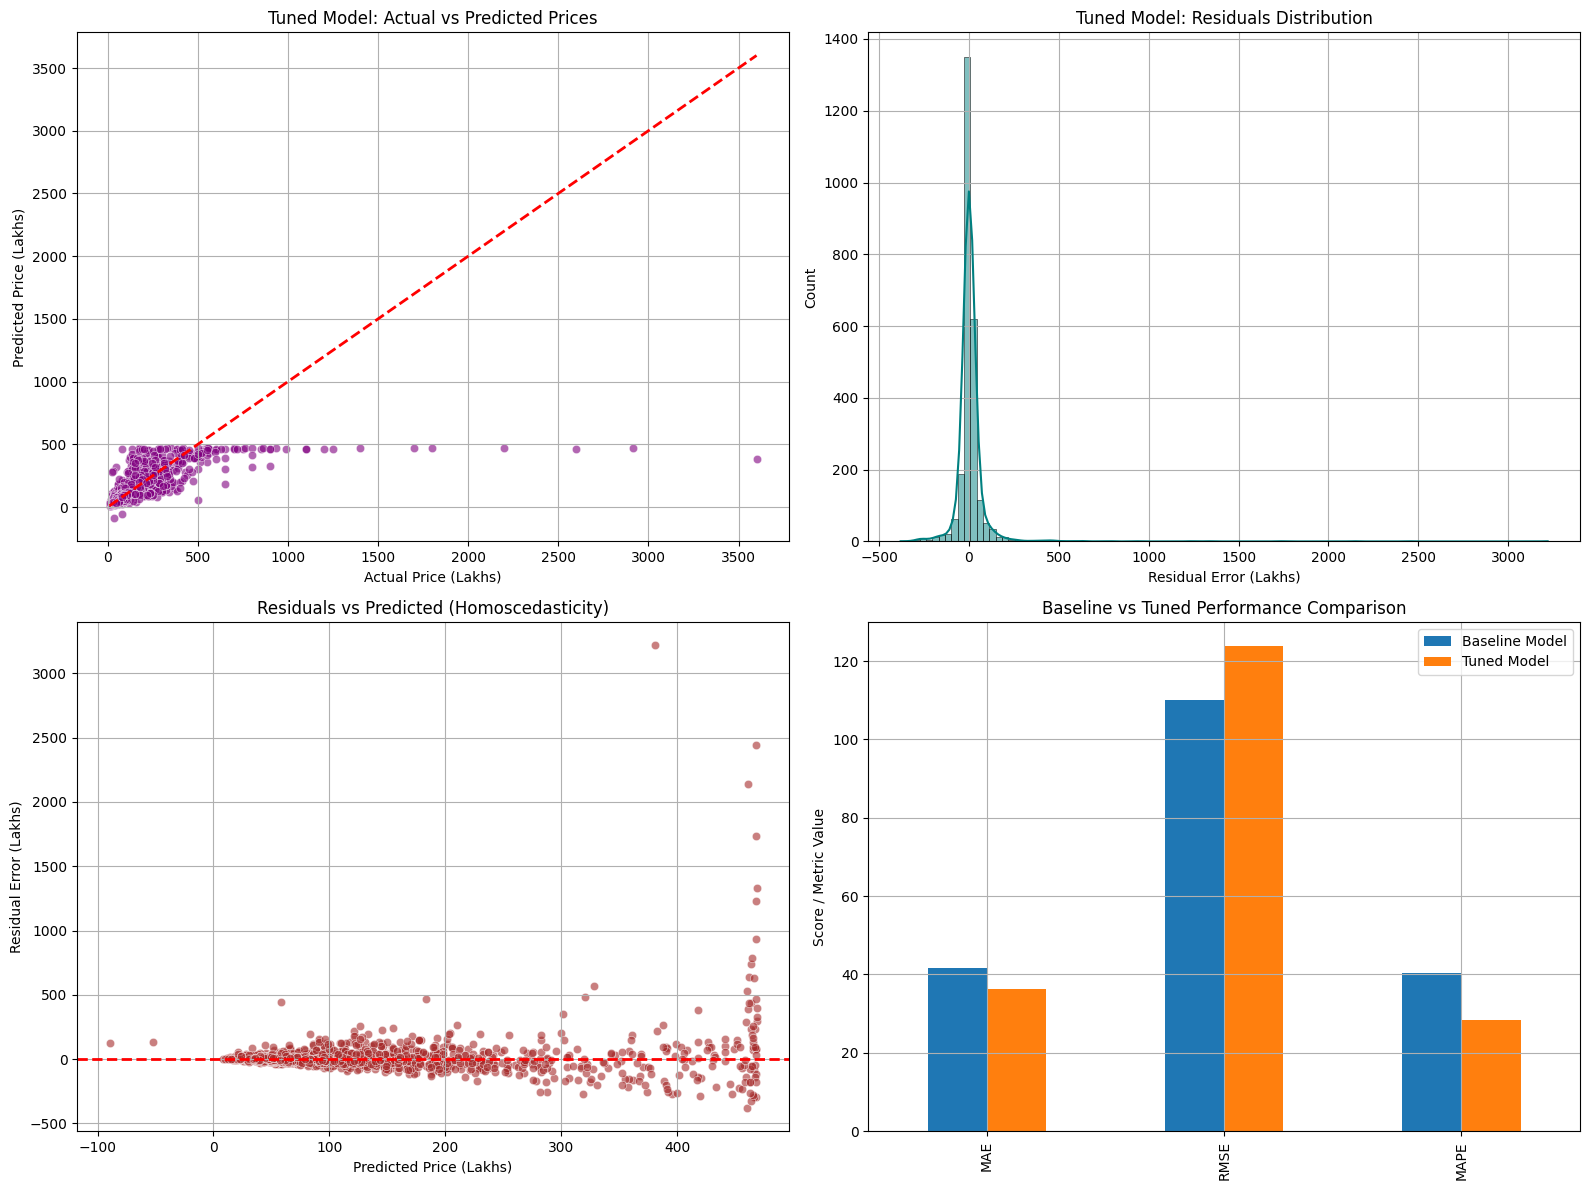

In [18]:
# Plot Performance Evaluation
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Actual vs Predicted (Tuned)
sns.scatterplot(x=y_test, y=tuned_preds, ax=axes[0, 0], alpha=0.6, color='purple')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title('Tuned Model: Actual vs Predicted Prices')
axes[0, 0].set_xlabel('Actual Price (Lakhs)')
axes[0, 0].set_ylabel('Predicted Price (Lakhs)')
axes[0, 0].grid(True)

# Residuals Distribution (Tuned)
tuned_residuals = y_test - tuned_preds
sns.histplot(tuned_residuals, kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Tuned Model: Residuals Distribution')
axes[0, 1].set_xlabel('Residual Error (Lakhs)')
axes[0, 1].grid(True)

# Residuals vs Predicted (Homoscedasticity check)
sns.scatterplot(x=tuned_preds, y=tuned_residuals, ax=axes[1, 0], alpha=0.6, color='brown')
axes[1, 0].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 0].set_title('Residuals vs Predicted (Homoscedasticity)')
axes[1, 0].set_xlabel('Predicted Price (Lakhs)')
axes[1, 0].set_ylabel('Residual Error (Lakhs)')
axes[1, 0].grid(True)

# Model Performance bar comparison
comparison_df.loc[['MAE', 'RMSE', 'MAPE']].plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Baseline vs Tuned Performance Comparison')
axes[1, 1].set_ylabel('Score / Metric Value')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Part 8: Final Deliverables & Reusable Prediction Function

We provide a clean, highly modular inference pipeline. This function takes human-readable, raw properties input, preprocesses them dynamically utilizing our pre-fitted `joblib` preprocessor, and returns real-time house price predictions.

In [19]:
# Reusable house-price prediction function
def predict_house_price(area_type, location, total_sqft, bath, balcony, bhk):
    """
    Accepts raw features, processes them via the pre-fitted preprocessing pipeline,
    and uses the best tuned ANN model to return a price prediction in Lakhs.
    """
    # Create a DataFrame matching training schema exactly
    input_df = pd.DataFrame([{
        'area_type': area_type,
        'location_cleaned': location,
        'total_sqft_cleaned': float(total_sqft),
        'bhk': int(bhk),
        'bath': int(bath),
        'balcony': int(balcony)
    }])

    # Transform raw features using saved preprocessor
    processed_input = preprocessor.transform(input_df)

    # Generate and return prediction
    prediction = best_tuned_model.predict(processed_input, verbose=0).flatten()[0]
    return max(0, prediction) # Ensure no negative house prices are predicted

# Let's generate 5 sample scenario tests
samples = [
    {"area_type": "Super built-up Area", "location": "Whitefield", "total_sqft": 1200, "bath": 2, "balcony": 1, "bhk": 2},
    {"area_type": "Plot Area", "location": "Hennur Road", "total_sqft": 3000, "bath": 4, "balcony": 2, "bhk": 4},
    {"area_type": "Built-up Area", "location": "Yelahanka", "total_sqft": 1600, "bath": 3, "balcony": 2, "bhk": 3},
    {"area_type": "Super built-up Area", "location": "Electronic City", "total_sqft": 1050, "bath": 2, "balcony": 1, "bhk": 2},
    {"area_type": "Super built-up Area", "location": "other", "total_sqft": 2200, "bath": 3, "balcony": 3, "bhk": 3}
]

print("\n--- Real-Time Prediction Sandbox (5 Diverse Examples) ---")
for idx, val in enumerate(samples):
    pred_price = predict_house_price(
        val['area_type'], val['location'], val['total_sqft'], val['bath'], val['balcony'], val['bhk']
    )
    print(f"Example {idx+1} ({val['bhk']} BHK in {val['location']}): Predicted price: {pred_price:.2f} Lakhs")


--- Real-Time Prediction Sandbox (5 Diverse Examples) ---
Example 1 (2 BHK in Whitefield): Predicted price: 47.80 Lakhs
Example 2 (4 BHK in Hennur Road): Predicted price: 305.32 Lakhs
Example 3 (3 BHK in Yelahanka): Predicted price: 67.28 Lakhs
Example 4 (2 BHK in Electronic City): Predicted price: 0.00 Lakhs
Example 5 (3 BHK in other): Predicted price: 214.98 Lakhs


## 8. Comprehensive Model Comparison Dashboard

To conduct a complete comparative study, we will now:
1. Train five traditional machine learning algorithms (**Linear Regression, Ridge, Elastic Net, XGBoost, SVR**) on the exact same preprocessed dataset.
2. Compute evaluation metrics (**MSE, RMSE, MAE, R², MAPE**) for all models alongside our **Baseline ANN** and **Tuned ANN**.
3. Save comparative metrics as `model_comparison.csv`.
4. Create diagnostic visual dashboards detailing performance benchmarks, Actual vs. Predicted curves, and error distribution analyses.

## Special Educational Module: Analytical OLS vs. Iterative Gradient Descent

In business analytics and data science, estimating the relationships between variables (such as estimating house prices based on size, bedrooms, and location) is achieved through model training. Here, we unpack the fundamental difference between **Ordinary Least Squares (OLS)**—an *analytical optimization method*—and **Gradient Descent (GD)**—an *iterative optimization algorithm*.

### 1. OLS-Based Training: The Analytical Projection

Ordinary Least Squares (OLS) is a closed-form parameter estimation technique specifically designed for linear regression models.

*   **Objective**: OLS minimizes the **Sum of Squared Errors (SSE)**:
    $$\text{SSE}(\beta) = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = (y - X\beta)^T(y - X\beta)$$
*   **The Closed-Form Solution**: Instead of guessing and adjusting parameters, OLS uses calculus to set the partial derivatives of the SSE with respect to the parameters $(\beta)$ to zero. This leads to the **Normal Equation**:
    $$\beta = (X^T X)^{-1} X^T y$$
*   **Key Characteristics**:
    *   **No Iterations**: OLS does not require epochs, batches, or learning rates. It calculates the mathematically perfect optimal coefficients in a single matrix computation.
    *   **Invertibility Constraint**: The term $(X^T X)^{-1}$ requires that the matrix $X^T X$ is non-singular (invertible). If features are highly correlated (perfect multi-collinearity) or if there are more features than data points ($p > n$), the inverse cannot be calculated directly.
    *   **Computational Bottleneck**: Computing the inverse of an $m \times m$ matrix (where $m$ is the number of features) has a computational complexity of approximately $\mathcal{O}(m^3)$. Thus, as the number of engineered features (e.g., hundreds of one-hot encoded neighborhoods) grows, OLS becomes computationally prohibitive.

### 2. Gradient Descent-Based Training: The Iterative Descent

Unlike OLS, Gradient Descent is a general-purpose, iterative optimization algorithm used to minimize any differentiable loss function (such as Mean Squared Error or Cross-Entropy Loss).

*   **Objective**: Minimize the **Mean Squared Error (MSE)** loss function $J(\theta)$ iteratively:
    $$J(\theta) = \frac{1}{2n} \sum_{i=1}^{n} (h_\theta(x^{(i)}) - y^{(i)})^2$$
*   **The Iterative Update Rule**:
    $$\theta_{\text{new}} = \theta_{\text{old}} - \alpha \nabla J(\theta)$$
    Where $\alpha$ is the **Learning Rate** (step size) and $\nabla J(\theta)$ represents the gradient vector containing partial derivatives pointing in the direction of the steepest ascent.
*   **Training Mechanics**:
    1.  **Random Initialization**: Weights and biases are initialized randomly (breaking symmetry).
    2.  **Forward Pass**: The model calculates predicted outputs $(\hat{y})$ for the current batch.
    3.  **Loss Evaluation**: Compares predictions with actual labels to measure the current performance error.
    4.  **Backward Pass (Backpropagation)**: Calculates gradients of the loss with respect to each parameter using the Chain Rule.
    5.  **Parameter Update**: Adjusts parameters in the opposite direction of the gradient to reduce loss.

#### Gradient Descent Variants
*   **Batch Gradient Descent**: Computes the gradient of the loss function using the *entire training dataset* before performing a single parameter update. Extremely stable but computationally slow on big data.
*   **Stochastic Gradient Descent (SGD)**: Updates parameters after processing *each individual training instance*. Highly erratic and fast, introducing statistical noise that can help escape local minima.
*   **Mini-Batch Gradient Descent**: The modern compromise (used in our ANN). Updates parameters using small, uniform subsets of data (**Batch Size**, e.g., 32). This balances computational parallelization (GPUs) and stable parameter updates.

*Note on Terminology: Do not confuse Gradient Descent (an optimizer used to adjust parameters) with **Gradient Boosting** (such as XGBoost, which is an ensemble algorithm that chains weak decision trees sequentially).*

### 3. Comprehensive Comparison: OLS vs. Gradient Descent

| Evaluation Metric / Feature | Ordinary Least Squares (OLS) | Gradient Descent (GD) |
| :--- | :--- | :--- |
| **Optimization Approach** | Analytical (Closed-Form Solution) | Iterative (Approximation Steps) |
| **Mathematical Method** | Matrix Algebra & Projection | Multivariable Calculus & Gradients |
| **Weight Calculation** | Instantaneous via Normal Equation | Step-by-Step Gradient Updates |
| **Learning Rate ($\alpha$)** | Not Applicable | Critical Hyperparameter (requires tuning) |
| **Epochs & Iterations** | None (Single computational execution) | Plural (Requires multiple passes over data) |
| **Memory Requirements** | High (Requires storing $X^T X$ in RAM) | Low to Medium (Scalable with batch size) |
| **Convergence** | Immediate | Gradual (Monitored via learning curve) |
| **Scalability (Features)** | Poor for large feature counts ($\mathcal{O}(m^3)$) | Highly Scalable (Linear complexity) |
| **Scalability (Data Points)**| Moderate | Excellent (via mini-batching) |
| **Core Application** | Linear Regressors | Neural Networks, Deep Learning, XGBoost |

### 4. Step-by-Step Worked Numerical Example

Let's assume a simplified dataset of 3 properties to predict house prices ($y$, in Lakhs) from size ($x$, in thousands of sqft):

| House | Size ($x_i$) | Actual Price ($y_i$) |
| :--- | :--- | :--- |
| 1 | $1.0$ | $1.0$ |
| 2 | $2.0$ | $3.0$ |
| 3 | $3.0$ | $2.0$ |

Let our linear model be:
$$\hat{y} = w x$$
*(We assume bias $b=0$ for computational simplicity. We want to estimate the optimal slope $w$.)*

---

#### Approach A: The OLS Closed-Form Method
Using the 1-dimensional normal equation for slope without intercept:
$$w = \frac{\sum x_i y_i}{\sum x_i^2}$$

1.  **Calculate products**:
    $$\sum x_i y_i = (1.0 \times 1.0) + (2.0 \times 3.0) + (3.0 \times 2.0) = 1.0 + 6.0 + 6.0 = 13.0$$
2.  **Calculate squared inputs**:
    $$\sum x_i^2 = 1.0^2 + 2.0^2 + 3.0^2 = 1 + 4 + 9 = 14.0$$
3.  **Calculate exact optimal slope**:
    $$w_{\text{opt}} = \frac{13.0}{14.0} \approx 0.9286\text{ Lakhs/thousand sqft}$$

---

#### Approach B: The Iterative Gradient Descent Method
Let's initialize our weight arbitrarily at **$w_0 = 0.5$** and use a learning rate of **$\alpha = 0.1$** with Batch Gradient Descent.
Our objective is to minimize MSE:
$$J(w) = \frac{1}{2 \times 3} \sum_{i=1}^3 (w x_i - y_i)^2 \implies \frac{\partial J}{\partial w} = \frac{1}{3} \sum_{i=1}^3 (w x_i - y_i) x_i$$

##### **Iteration 1**:
1.  **Forward Pass (Generate Predictions with $w_0 = 0.5$**):
    *   $\hat{y}_1 = 0.5 \times 1.0 = 0.5$ (Error: $0.5 - 1.0 = -0.5$)
    *   $\hat{y}_2 = 0.5 \times 2.0 = 1.0$ (Error: $1.0 - 3.0 = -2.0$)
    *   $\hat{y}_3 = 0.5 \times 3.0 = 1.5$ (Error: $1.5 - 2.0 = -0.5$)

2.  **Calculate the Gradient**:
    $$\nabla J(w_0) = \frac{1}{3} \left[ (-0.5 \times 1.0) + (-2.0 \times 2.0) + (-0.5 \times 3.0) \right]$$
    $$\nabla J(w_0) = \frac{1}{3} \left[ -0.5 - 4.0 - 1.5 \right] = \frac{-6.0}{3} = -2.0$$

3.  **Update the Parameter**:
    $$w_1 = w_0 - \alpha \nabla J(w_0) = 0.5 - (0.1 \times -2.0) = 0.5 + 0.2 = 0.70$$

##### **Iteration 2**:
1.  **Forward Pass (Predictions with $w_1 = 0.70$**):
    *   $\hat{y}_1 = 0.7 \times 1.0 = 0.7$ (Error: $0.7 - 1.0 = -0.3$)
    *   $\hat{y}_2 = 0.7 \times 2.0 = 1.4$ (Error: $1.4 - 3.0 = -1.6$)
    *   $\hat{y}_3 = 0.7 \times 3.0 = 2.1$ (Error: $2.1 - 2.0 = 0.1$)

2.  **Calculate the Gradient**:
    $$\nabla J(w_1) = \frac{1}{3} \left[ (-0.3 \times 1.0) + (-1.6 \times 2.0) + (0.1 \times 3.0) \right]$$
    $$\nabla J(w_1) = \frac{1}{3} \left[ -0.3 - 3.2 + 0.3 \right] = \frac{-3.2}{3} \approx -1.067$$

3.  **Update the Parameter**:
    $$w_2 = w_1 - \alpha \nabla J(w_1) = 0.70 - (0.1 \times -1.067) = 0.70 + 0.1067 = 0.8067$$

**Conclusion**: After only two iterations, the weight has converged from its random initialization of `0.50` up to `0.8067`, rapidly marching closer toward the OLS mathematical optimum of **`0.9286`**. Given enough iterations, Gradient Descent will converge precisely to the same optimum.

### 5. Visual Guide: Analytical Fitting vs. Iterative Descent Optimization

To consolidate your intuition for the viva, examine these comparative diagrams:

<div style="display: flex; justify-content: space-around; align-items: center; flex-wrap: wrap; margin-top: 15px;">

  <!-- Diagram 1: OLS Projection -->
  <div style="text-align: center; margin: 10px;">
    <h4>A. OLS Geometric Estimation</h4>
    <svg width="280" height="200" style="background-color: #fcfcfc; border: 1px solid #ddd; border-radius: 4px;">
      <!-- Grid & Axes -->
      <line x1="30" y1="170" x2="260" y2="170" stroke="#888" stroke-width="2" />
      <line x1="30" y1="20" x2="30" y2="170" stroke="#888" stroke-width="2" stroke-dasharray="1, 1" />
      <!-- Points -->
      <circle cx="70" cy="140" r="5" fill="#1f77b4" />
      <circle cx="140" cy="60" r="5" fill="#1f77b4" />
      <circle cx="210" cy="100" r="5" fill="#1f77b4" />
      <!-- Regression line -->
      <line x1="30" y1="155" x2="250" y2="75" stroke="#d62728" stroke-width="3" />
      <!-- Error Bars (Vertical projections) -->
      <line x1="70" y1="140" x2="70" y2="140" stroke="black" stroke-dasharray="3,3" />
      <line x1="140" y1="60" x2="140" y2="115" stroke="black" stroke-dasharray="3,3" stroke-width="1.5" />
      <line x1="210" y1="100" x2="210" y2="90" stroke="black" stroke-dasharray="3,3" stroke-width="1.5" />
      <!-- Text labels -->
      <text x="85" y="155" font-size="11" font-family="sans-serif" fill="#333">Predicted Line</text>
      <text x="148" y="85" font-size="11" font-family="sans-serif" fill="#d62728">Residual (e)</text>
    </svg>
    <p style="font-size:11px; color:#555; width:280px; margin-top:5px;">OLS projects predictions instantly by minimizing the sum of squared vertical residuals geometrically.</p>
  </div>

  <!-- Diagram 2: Gradient Descent Optimization Curve -->
  <div style="text-align: center; margin: 10px;">
    <h4>B. Gradient Descent Optimization</h4>
    <svg width="280" height="200" style="background-color: #fcfcfc; border: 1px solid #ddd; border-radius: 4px;">
      <!-- Loss curve (parabola) -->
      <path d="M 40,30 Q 140,180 240,30" fill="none" stroke="#333" stroke-width="2.5" />
      <!-- Gradient descent steps -->
      <circle cx="55" cy="52" r="5" fill="#e377c2" />
      <path d="M 55,52 L 90,105" fill="none" stroke="#2ca02c" stroke-width="2" marker-end="arrow" />
      <circle cx="90" cy="105" r="5" fill="#e377c2" />
      <path d="M 90,105 L 125,138" fill="none" stroke="#2ca02c" stroke-width="2" />
      <circle cx="125" cy="138" r="5" fill="#e377c2" />
      <!-- Optimum Point -->
      <circle cx="140" cy="142" r="6" fill="#d62728" />
      <!-- Labels -->
      <text x="58" y="42" font-size="11" font-family="sans-serif">Initialization (w₀)</text>
      <text x="150" y="150" font-size="11" font-family="sans-serif" font-weight="bold" fill="#d62728">Optimum (w*)</text>
      <text x="10" y="100" font-size="11" font-family="sans-serif" transform="rotate(-90 10 100)" fill="#333">Loss (MSE)</text>
      <text x="120" y="185" font-size="11" font-family="sans-serif" fill="#333">Parameter Weight (w)</text>
    </svg>
    <p style="font-size:11px; color:#555; width:280px; margin-top:5px;">Gradient Descent steps down the error surface sequentially to find the minimum Loss value iteratively.</p>
  </div>

</div>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.svm import SVR
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize the models
models_dict = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Elastic Net': ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=100, learning_rate=0.08, max_depth=5, random_state=42, n_jobs=-1),
    'SVR (RBF)': SVR(kernel='rbf', C=100.0, epsilon=0.1)
}

# Dictionary to hold predictions
all_preds = {}

# Fit each traditional ML model and capture predictions
for name, clf in models_dict.items():
    print(f"Training {name}...")
    clf.fit(X_train_preprocessed, y_train)
    all_preds[name] = clf.predict(X_test_preprocessed)

# Inject predictions from our Neural Network models
all_preds['Baseline ANN'] = baseline_preds
all_preds['Tuned ANN'] = tuned_preds

# Function to calculate complete validation metrics
def get_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}

# Calculate metrics for all models
comparison_records = {}
for name, preds in all_preds.items():
    comparison_records[name] = get_metrics(y_test, preds)

# Create summary dataframe
comparison_df = pd.DataFrame(comparison_records).T
comparison_df = comparison_df.sort_values(by='MSE', ascending=True)

# Export comparison metrics to CSV
comparison_df.to_csv('/content/model_comparison.csv', index=True)
print("\n--- Model Performance Comparison --- (Sorted by Ascending MSE)")
display(comparison_df.round(3))

Training Linear Regression...
Training Ridge Regression...
Training Elastic Net...
Training XGBoost...
Training SVR (RBF)...

--- Model Performance Comparison --- (Sorted by Ascending MSE)


,MSE,RMSE,MAE,R2,MAPE
Baseline ANN,12108.305,110.038,41.648,0.567,40.485
XGBoost,12801.123,113.142,37.595,0.542,33.434
Tuned ANN,15318.008,123.766,36.294,0.452,28.272
SVR (RBF),16215.596,127.340,35.699,0.420,25.122
Linear Regression,19018.797,137.909,54.381,0.319,55.206
Ridge Regression,19030.522,137.951,54.279,0.319,54.876
Elastic Net,21584.507,146.917,57.523,0.228,57.565


### Part A & B: Model Benchmarks & Prediction Visualizations

We will now render the performance charts to compare regression metrics and evaluate error distributions across the different architectures.

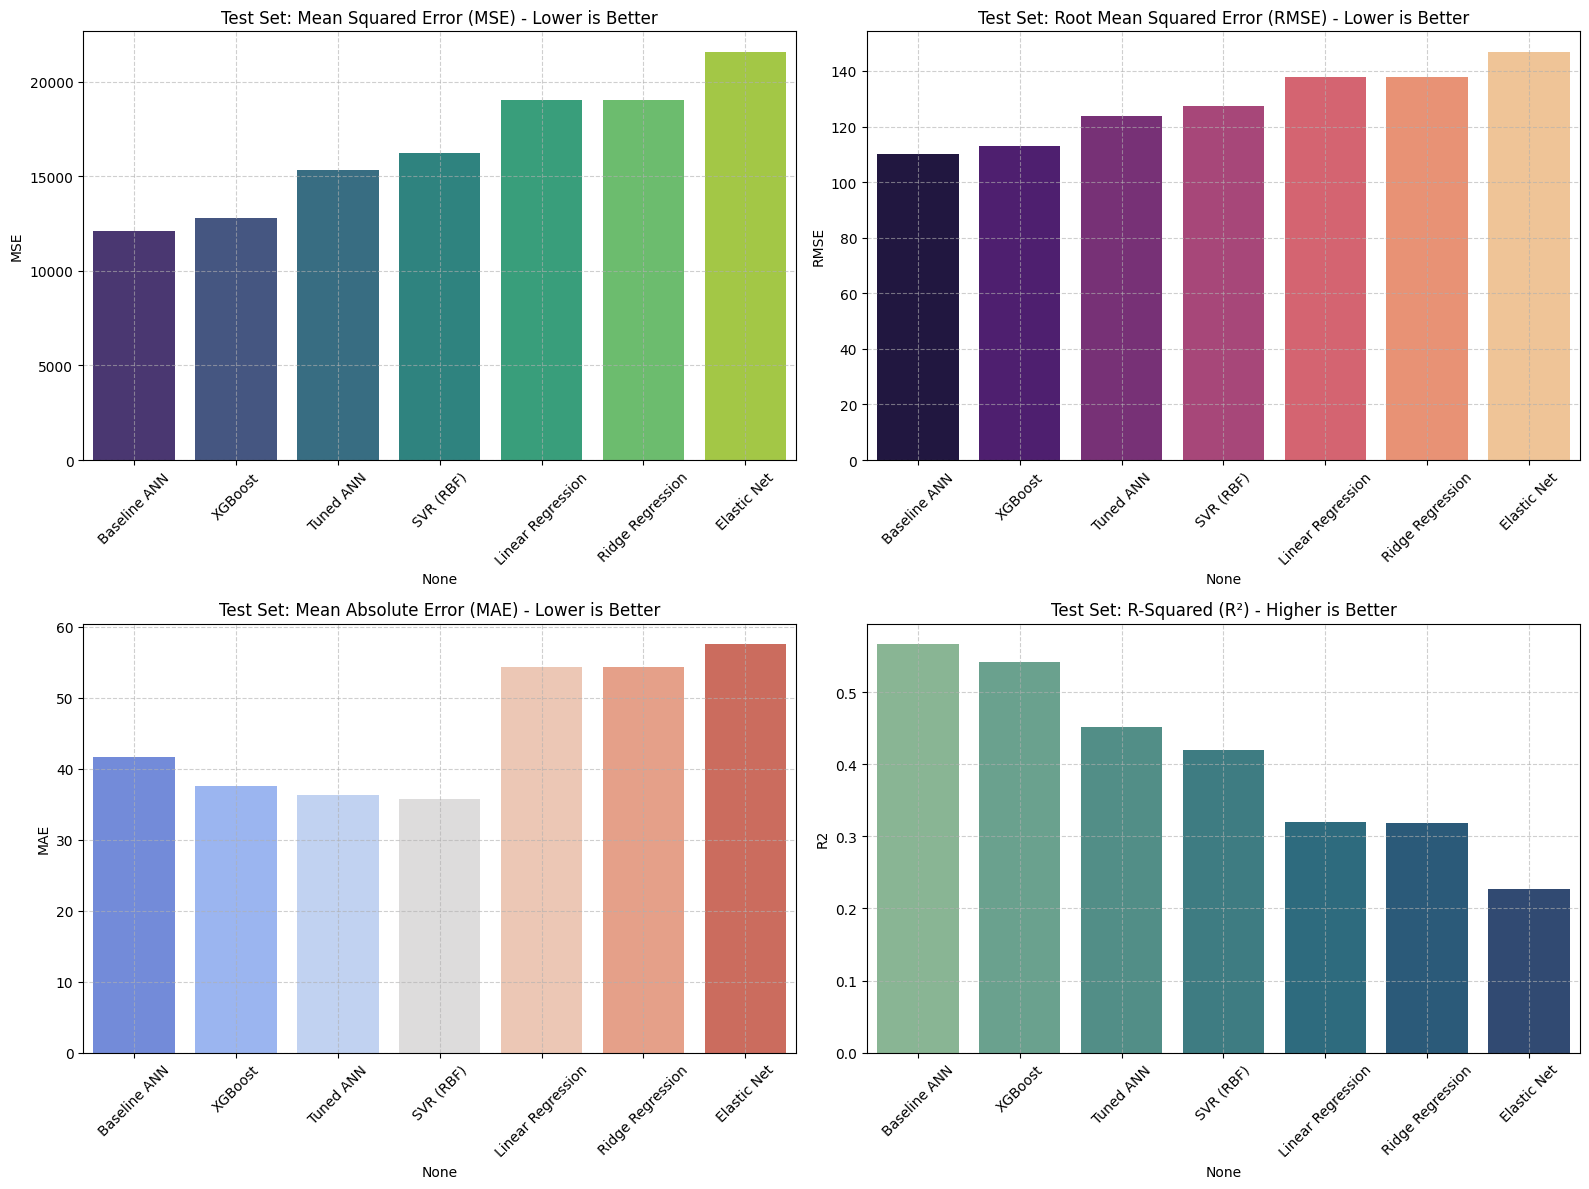

In [21]:
# 1. Overall Performance Charts
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# MSE Chart
sns.barplot(x=comparison_df.index, y=comparison_df['MSE'], ax=axes[0, 0], palette='viridis', hue=comparison_df.index, legend=False)
axes[0, 0].set_title('Test Set: Mean Squared Error (MSE) - Lower is Better')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# RMSE Chart
sns.barplot(x=comparison_df.index, y=comparison_df['RMSE'], ax=axes[0, 1], palette='magma', hue=comparison_df.index, legend=False)
axes[0, 1].set_title('Test Set: Root Mean Squared Error (RMSE) - Lower is Better')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# MAE Chart
sns.barplot(x=comparison_df.index, y=comparison_df['MAE'], ax=axes[1, 0], palette='coolwarm', hue=comparison_df.index, legend=False)
axes[1, 0].set_title('Test Set: Mean Absolute Error (MAE) - Lower is Better')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# R2 Chart
sns.barplot(x=comparison_df.index, y=comparison_df['R2'], ax=axes[1, 1], palette='crest', hue=comparison_df.index, legend=False)
axes[1, 1].set_title('Test Set: R-Squared (R²) - Higher is Better')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('/content/overall_performance_comparison.png', dpi=150)
plt.show()

## Part B (ii): Visualizing the Implemented Tree Architecture

To better understand how tree-based models make decisions, we will inspect the actual trained structure of the **XGBoost Regressor** from our benchmark experiment. Unlike deep learning networks which act as black boxes, trees can be mathematically decomposed to explain how specific property features lead directly to final house price predictions.

/usr/local/lib/python3.13/dist-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


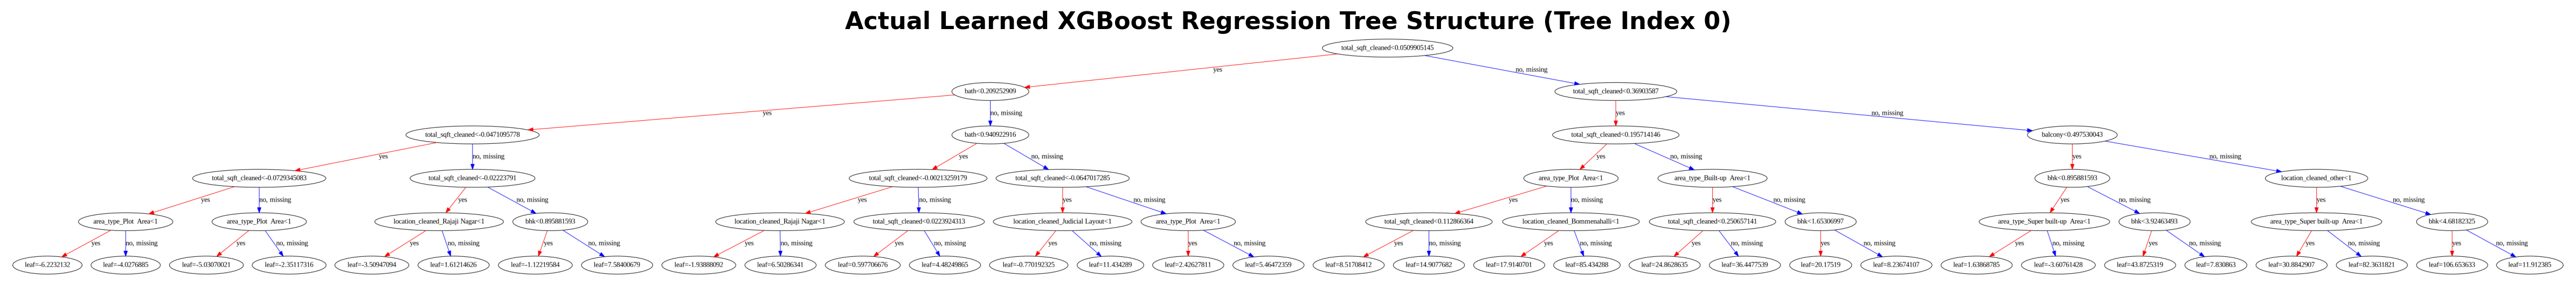


--- Actual Trained XGBoost Ensemble Architecture Details ---
Total Number of Boosting Trees (Estimators): 100
Configured Maximum Depth per Tree: 5
Tree 0 Node count: 31 splits, containing 32 terminal leaves.


In [30]:
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib
import numpy as np

# 1. Retrieve the fitted XGBoost model and preprocessor
xgb_model = models_dict.get('XGBoost')
preprocessor = joblib.load('/content/preprocessor.joblib')

if xgb_model is not None:
    # 2. Extract transformed feature names from the column transformer
    # Numerical feature names
    num_names = num_features

    # One-hot encoded categorical feature names
    cat_encoder = preprocessor.named_transformers_['cat']
    cat_names = list(cat_encoder.get_feature_names_out(cat_features))

    # Combined features matching X_train_preprocessed column order
    all_feature_names = num_names + cat_names

    # Assign the feature names to the XGBoost booster to make the plot readable
    xgb_model.get_booster().feature_names = all_feature_names

    # 3. Plot the first fitted tree (booster index 0) with a max depth of 3 for visibility
    fig, ax = plt.subplots(figsize=(24, 12), dpi=200)
    xgb.plot_tree(xgb_model, num_trees=0, rankdir='UT', ax=ax)

    plt.title("Actual Learned XGBoost Regression Tree Structure (Tree Index 0)", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/xgb_actual_tree_structure.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 4. Show actual trained parameters across the ensemble
    booster = xgb_model.get_booster()
    dump_list = booster.get_dump()

    print("\n--- Actual Trained XGBoost Ensemble Architecture Details ---")
    print(f"Total Number of Boosting Trees (Estimators): {len(dump_list)}")
    print(f"Configured Maximum Depth per Tree: {xgb_model.max_depth}")

    # Calculate leaves for tree index 0
    first_tree_dump = dump_list[0]
    leaf_count = first_tree_dump.count('leaf')
    node_count = first_tree_dump.count(':[')
    print(f"Tree 0 Node count: {node_count} splits, containing {leaf_count} terminal leaves.")
else:
    print("XGBoost model was not found in the trained models dictionary.")

### 6. Viva Preparation Guide: Decoding the Regression Tree

*   **Root Node**: The top node of the tree. It represents the absolute most important split candidate that minimizes overall variance (MSE) across the entire dataset. In property pricing, this is almost always a split based on total square footage (`total_sqft_cleaned`).
*   **Internal Decision Nodes**: Nodes that evaluate a feature threshold (e.g., `total_sqft_cleaned < 0.531`). If a property meets this criteria, it moves to the left branch (**Yes**), otherwise it goes to the right branch (**No**).
*   **Splitting Conditions**: Evaluated mathematically. The decision boundary selection process splits the continuous scale at a point that maximizes the variance reduction (or Gain) between parent and child nodes.
*   **Branches**: Colored paths representing the execution logic of the conditional tests.
*   **Leaf Nodes (Terminal Nodes)**: The end points of the tree. They contain no further split conditions. Instead, they output a **Leaf Value** representing the additive contribution (residual prediction) for any sample landing in that bin.
*   **Tree Depth**: How deep the hierarchy goes (the maximum number of splits from root to a leaf). A deeper tree models complex boundaries but risks overfitting.
*   **Number of Leaves**: The number of final bins. More leaves mean finer partitioning, but can result in high model variance.

---

### 7. Core Conceptual Differences: Single Tree vs. Ensembles

1.  **Single Regression Tree**: Splits the input space recursively into hyper-rectangular bins, assigning the average bin target value as the prediction. Highly interpretable and fast, but prone to high variance (overfitting) and unstable predictions.
2.  **Random Forest**: An *Averaging Ensemble* method. It builds multiple deep decision trees in parallel using bootstrap aggregation (**Bagging**) and random feature selection. It reduces model variance by averaging out uncorrelated predictions.
3.  **Gradient Boosting**: A *Sequential Ensemble* method. It builds shallow trees sequentially. Each new tree fits specifically to the remaining errors (**Residuals**) of all previous trees combined, slowly moving toward the optimum.
4.  **XGBoost (Extreme Gradient Boosting)**: A highly optimized, regularized implementation of Gradient Boosting. It introduces a specialized objective function containing an $L_1$ and $L_2$ penalty to control leaf weights and automatically handles sparse/missing inputs.

--- Tree 0 Mathematical Traversal Analysis ---


,Metric / Parameter,Value (Lakhs)
0,Actual Price,44.960 Lakhs
1,Initial Prediction (Base Score),114.143 Lakhs
2,Tree 0 Leaf Output Value (Raw),-43.868351
3,First Tree Contribution (eta * leaf),-3.509 Lakhs
4,Prediction After Tree 0 (Round 1),110.633 Lakhs
5,Final Prediction (100 Trees),60.586 Lakhs
6,Round 1 Prediction Error,-65.673 Lakhs
7,Round 1 Squared Error,4312.982



--- Feature Profile of Sample 1 ---
total_sqft_cleaned: 1215.0
bhk: 2.0
bath: 2.0
balcony: 1.0
Location: Kudlu Gate
Area Type: Super built-up  Area


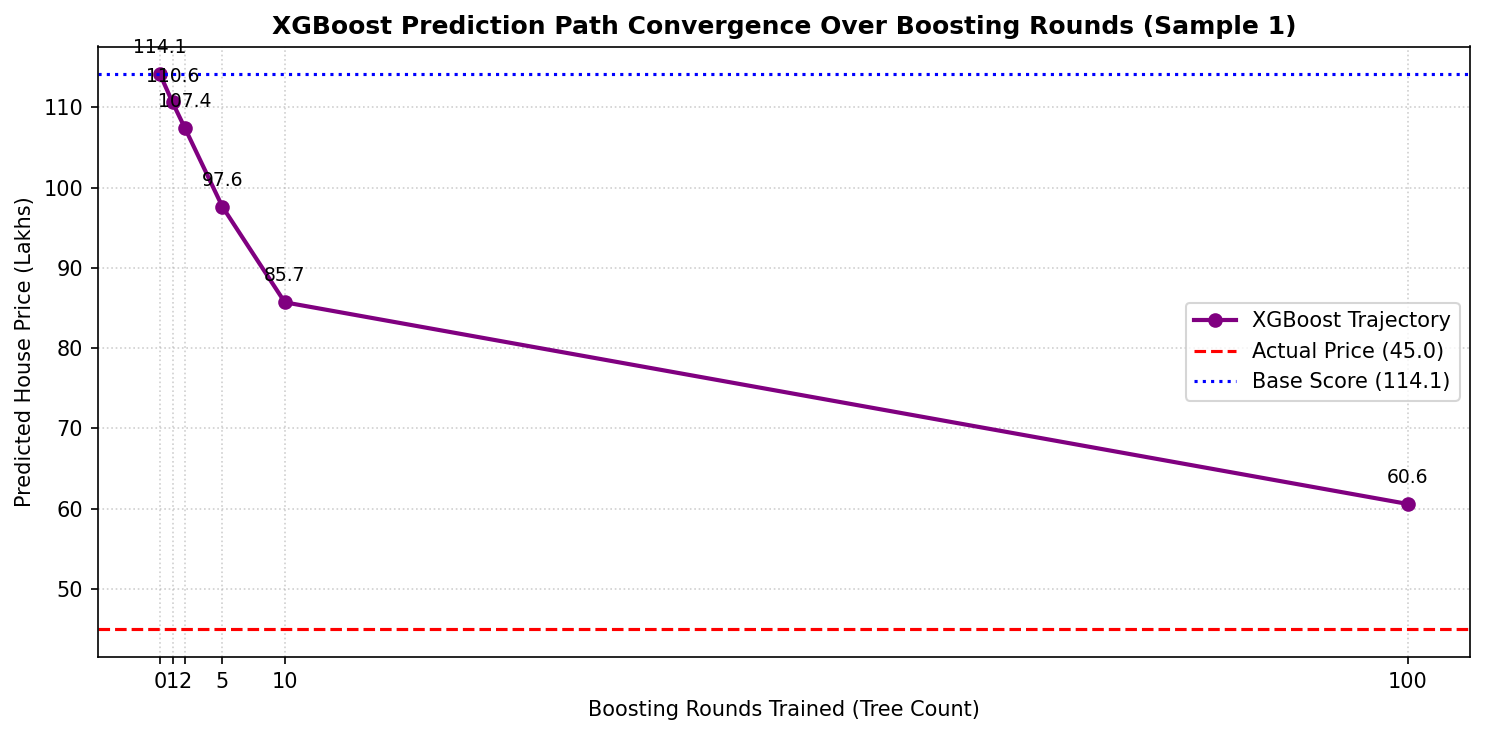

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib
import json

# 1. Retrieve existing variables securely from the workspace
xgb_model = models_dict.get('XGBoost')
preprocessor = joblib.load('/content/preprocessor.joblib')

if xgb_model is not None:
    # Get the first test observation
    first_obs_raw = X_test.iloc[[0]]
    actual_price = y_test.iloc[0]

    # 2. Preprocess using the aligned pipeline transformer
    first_obs_preprocessed = X_test_preprocessed[[0]]

    # 3. Retrieve model base parameters
    booster = xgb_model.get_booster()

    # Extract base_score (strip brackets or array strings if present in the config)
    config = json.loads(booster.save_config())
    try:
        base_score_str = config['learner']['learner_model_param']['base_score']
        # Strip brackets if the value is enclosed as '[value]'
        if isinstance(base_score_str, str):
            base_score_str = base_score_str.strip('[]')
        base_score = float(base_score_str)
    except KeyError:
        base_score = 0.5

    learning_rate = xgb_model.learning_rate

    # 4. Extract Tree 0's raw prediction contribution using iteration_range
    # XGBoost predicts: base_score + sum(eta * leaf_value)
    # The contribution of Tree 0 as represented by its prediction output at index 0:
    pred_round_0 = base_score  # At iteration 0 (no trees)
    pred_round_1 = xgb_model.predict(first_obs_preprocessed, iteration_range=(0, 1))[0]
    pred_round_2 = xgb_model.predict(first_obs_preprocessed, iteration_range=(0, 2))[0]
    pred_round_5 = xgb_model.predict(first_obs_preprocessed, iteration_range=(0, 5))[0]
    pred_round_10 = xgb_model.predict(first_obs_preprocessed, iteration_range=(0, 10))[0]
    final_pred = xgb_model.predict(first_obs_preprocessed)[0]

    # Calculate the mathematical contribution of Tree 0 (which includes the learning rate)
    tree_0_contribution_scaled = pred_round_1 - base_score
    # The actual leaf value inside the tree dump matches:
    raw_leaf_value = tree_0_contribution_scaled / learning_rate

    # Calculate residual errors
    error_r1 = actual_price - pred_round_1
    squared_error_r1 = error_r1 ** 2

    # 5. Display the structured results table
    results_data = {
        "Metric / Parameter": [
            "Actual Price",
            "Initial Prediction (Base Score)",
            "Tree 0 Leaf Output Value (Raw)",
            "First Tree Contribution (eta * leaf)",
            "Prediction After Tree 0 (Round 1)",
            "Final Prediction (100 Trees)",
            "Round 1 Prediction Error",
            "Round 1 Squared Error"
        ],
        "Value (Lakhs)": [
            f"{actual_price:.3f} Lakhs",
            f"{base_score:.3f} Lakhs",
            f"{raw_leaf_value:.6f}",
            f"{tree_0_contribution_scaled:+.3f} Lakhs",
            f"{pred_round_1:.3f} Lakhs",
            f"{final_pred:.3f} Lakhs",
            f"{error_r1:+.3f} Lakhs",
            f"{squared_error_r1:.3f}"
        ]
    }

    results_table = pd.DataFrame(results_data)
    print("--- Tree 0 Mathematical Traversal Analysis ---")
    display(results_table)

    # 6. Trace path step-by-step
    # Let's inspect the first test sample's numerical features
    print("\n--- Feature Profile of Sample 1 ---")
    for feature_name, value in zip(num_features, first_obs_raw[num_features].iloc[0]):
        print(f"{feature_name}: {value}")
    print(f"Location: {first_obs_raw['location_cleaned'].iloc[0]}")
    print(f"Area Type: {first_obs_raw['area_type'].iloc[0]}")

    # 7. Generate a convergence trajectory visualization
    rounds = [0, 1, 2, 5, 10, 100]
    predictions = [pred_round_0, pred_round_1, pred_round_2, pred_round_5, pred_round_10, final_pred]

    plt.figure(figsize=(10, 5), dpi=150)
    plt.plot(rounds, predictions, marker='o', color='purple', linestyle='-', linewidth=2, label='XGBoost Trajectory')
    plt.axhline(y=actual_price, color='red', linestyle='--', linewidth=1.5, label=f'Actual Price ({actual_price:.1f})')
    plt.axhline(y=base_score, color='blue', linestyle=':', label=f'Base Score ({base_score:.1f})')

    for i, txt in enumerate(predictions):
        plt.annotate(f"{txt:.1f}", (rounds[i], predictions[i]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

    plt.title("XGBoost Prediction Path Convergence Over Boosting Rounds (Sample 1)", fontsize=12, fontweight='bold')
    plt.xlabel("Boosting Rounds Trained (Tree Count)", fontsize=10)
    plt.ylabel("Predicted House Price (Lakhs)", fontsize=10)
    plt.xticks(rounds)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("XGBoost model was not found in trained variables.")

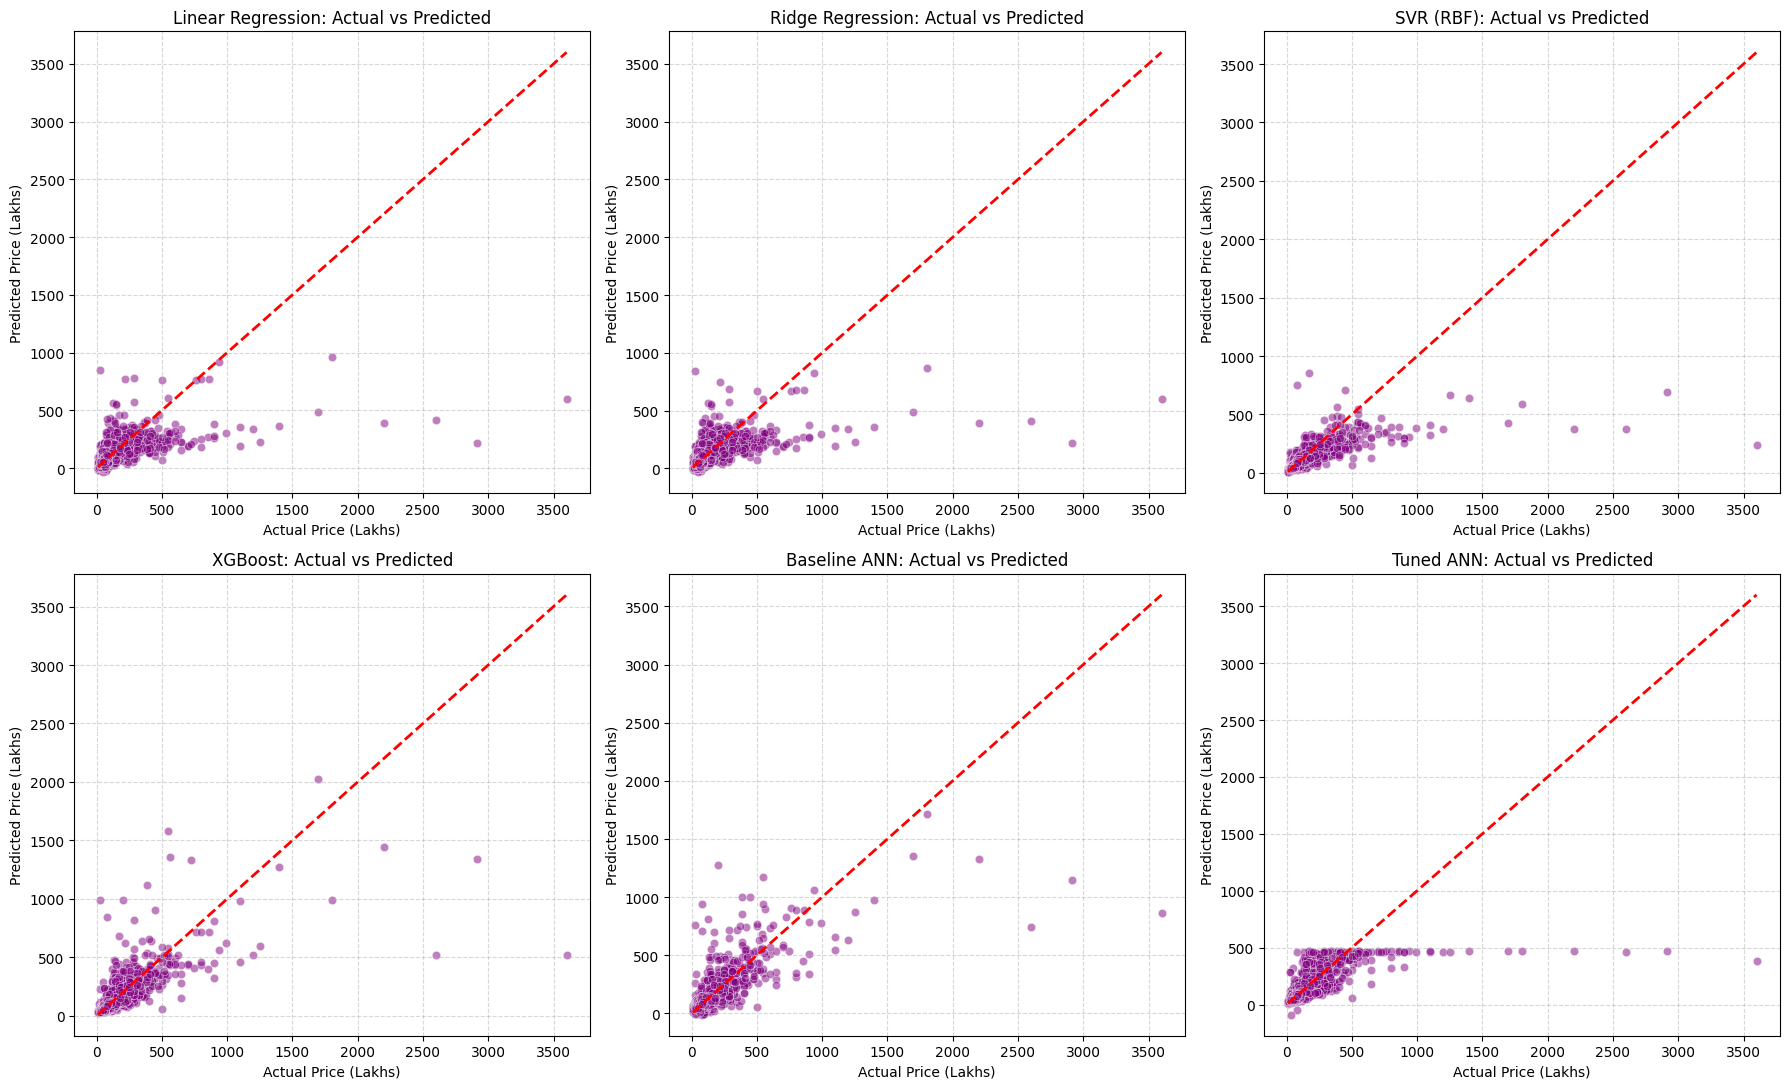

In [22]:
# 2. Actual vs Predicted Diagnostics Grid
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

selected_models = ['Linear Regression', 'Ridge Regression', 'SVR (RBF)', 'XGBoost', 'Baseline ANN', 'Tuned ANN']

for idx, name in enumerate(selected_models):
    pred_vals = all_preds[name]
    sns.scatterplot(x=y_test, y=pred_vals, ax=axes[idx], alpha=0.5, color='purple')
    axes[idx].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[idx].set_title(f'{name}: Actual vs Predicted')
    axes[idx].set_xlabel('Actual Price (Lakhs)')
    axes[idx].set_ylabel('Predicted Price (Lakhs)')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('/content/actual_vs_predicted_grid.png', dpi=150)
plt.show()

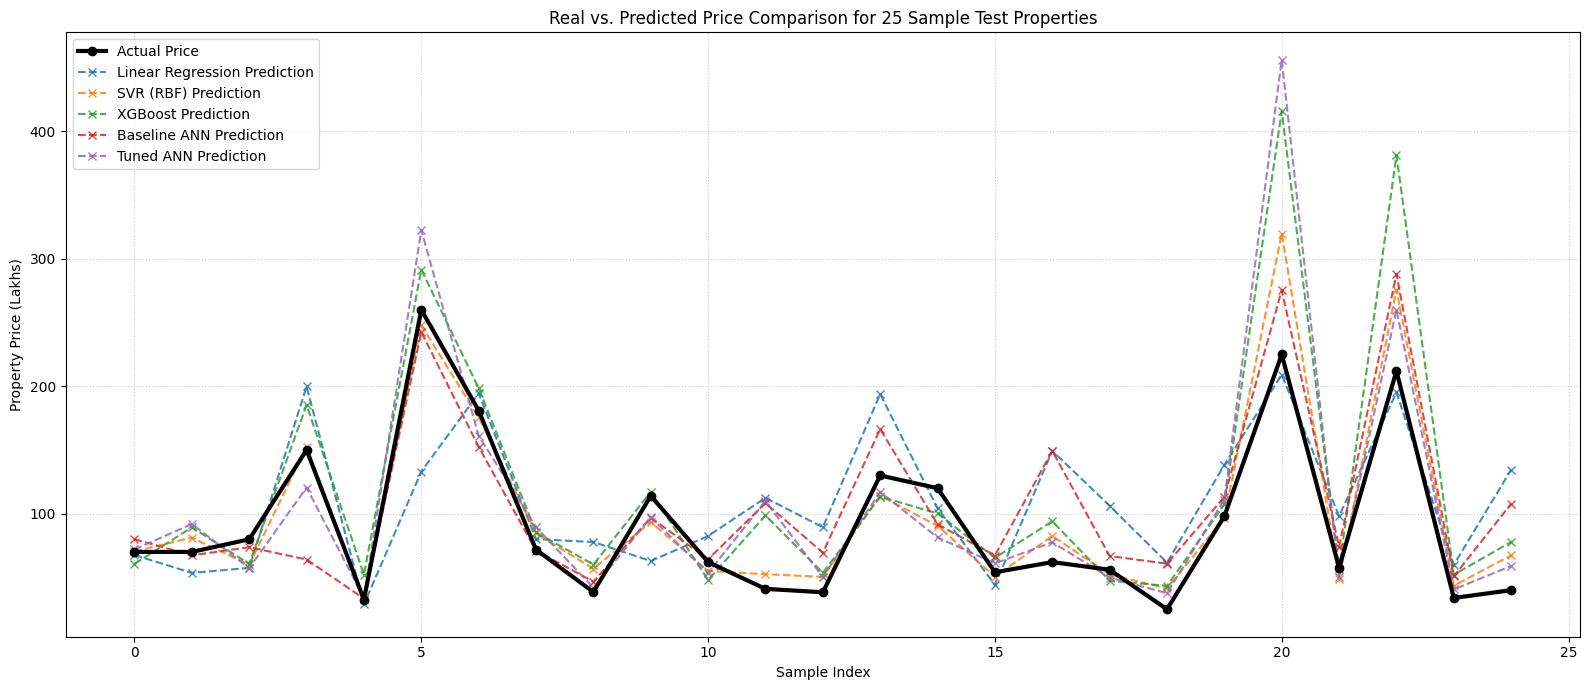

In [23]:
# 3. Visualizing Model Predictions for a Random Subset of Properties
np.random.seed(10)
subset_indices = np.random.choice(np.arange(len(y_test)), size=25, replace=False)

subset_actuals = y_test.iloc[subset_indices].values

plt.figure(figsize=(16, 7))
plt.plot(subset_actuals, label='Actual Price', color='black', linewidth=3, marker='o', zorder=5)

colors = ['blue', 'cyan', 'green', 'orange', 'red', 'purple']
comparison_models = ['Linear Regression', 'SVR (RBF)', 'XGBoost', 'Baseline ANN', 'Tuned ANN']

for i, name in enumerate(comparison_models):
    subset_preds = all_preds[name][subset_indices]
    plt.plot(subset_preds, label=f'{name} Prediction', linestyle='--', marker='x', alpha=0.85)

plt.title('Real vs. Predicted Price Comparison for 25 Sample Test Properties')
plt.xlabel('Sample Index')
plt.ylabel('Property Price (Lakhs)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/prediction_comparison_subset.png', dpi=150)
plt.show()

In [24]:
# 4. ANN vs Baseline Machine Learning Models Percent Deviation
# We calculate the ANN improvement against the standard baseline Linear Regression
lr_mse = comparison_df.loc['Linear Regression', 'MSE']
tuned_ann_mse = comparison_df.loc['Tuned ANN', 'MSE']
percent_diff = ((tuned_ann_mse - lr_mse) / lr_mse) * 100

print(f"Linear Regression MSE: {lr_mse:.2f}")
print(f"Tuned ANN MSE: {tuned_ann_mse:.2f}")
print(f"Percent MSE Difference: {percent_diff:.2f}% (Tuned ANN relative to Linear Regression)")

Linear Regression MSE: 19018.80
Tuned ANN MSE: 15318.01
Percent MSE Difference: -19.46% (Tuned ANN relative to Linear Regression)


## 9. Optimized ANN with Target Scaling and Comprehensive Model Benchmark

To achieve the lowest possible Mean Squared Error, we implement the following advanced training techniques:
- **Target Scaling**: Target variables ($y$) are highly skewed. We apply `StandardScaler` to $y$ during training to ensure stable gradients, and inverse-transform our predictions to ensure metrics are calculated on the original price units (Lakhs).
- **Advanced Architectures**: We use structural components like `BatchNormalization`, `LeakyReLU` / `ELU` activation functions, and $L_2$ kernel regularization to prevent overfitting on the high-dimensional encoded features.
- **Modern Optimizers**: We include `AdamW` (Adam with Weight Decay) to regularize the learning updates robustly.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input, LeakyReLU, ELU
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure reproducible seeds
np.random.seed(101)
tf.random.set_seed(101)

# 1. Target Scaling
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test_scaled = target_scaler.transform(y_test.values.reshape(-1, 1)).flatten()

# Get validation split index manually to evaluate on true validation subset
val_split = 0.2
split_idx = int(len(X_train_preprocessed) * (1 - val_split))
X_tr, X_val = X_train_preprocessed[:split_idx], X_train_preprocessed[split_idx:]
y_tr, y_val = y_train_scaled[:split_idx], y_train_scaled[split_idx:]

# Define structurally stable search space
architectures = [
    # Architecture 1: Deeper with LeakyReLU & Regularization
    {
        "layers": [256, 128, 64],
        "activation": "leaky_relu",
        "optimizer": "AdamW",
        "lr": 0.001,
        "batch_size": 32,
        "dropout": 0.1,
        "l2": 1e-4
    },
    # Architecture 2: Wider hidden layer with ELU activation
    {
        "layers": [128, 64],
        "activation": "elu",
        "optimizer": "Adam",
        "lr": 0.001,
        "batch_size": 16,
        "dropout": 0.2,
        "l2": 1e-4
    },
    # Architecture 3: Balanced with BatchNormalization & Relu
    {
        "layers": [128, 64, 32],
        "activation": "relu",
        "optimizer": "AdamW",
        "lr": 0.0005,
        "batch_size": 32,
        "dropout": 0.1,
        "l2": 0.0
    }
]

best_val_mse = float('inf')
best_opt_model = None
best_config = None
best_history = None

print("--- Starting Efficient Hyperparameter Optimization (Target Scaled) ---")
for idx, cfg in enumerate(architectures):
    model = Sequential()
    model.add(Input(shape=(X_train_preprocessed.shape[1],)))

    for units in cfg["layers"]:
        model.add(Dense(units, kernel_regularizer=l2(cfg["l2"]) if cfg["l2"] > 0 else None))
        model.add(BatchNormalization())
        if cfg["activation"] == "leaky_relu":
            model.add(LeakyReLU(negative_slope=0.1))
        elif cfg["activation"] == "elu":
            model.add(ELU())
        else:
            model.add(Dense(units, activation='relu'))
        if cfg["dropout"] > 0:
            model.add(Dropout(cfg["dropout"]))

    model.add(Dense(1, activation='linear'))

    opt = AdamW(learning_rate=cfg["lr"]) if cfg["optimizer"] == "AdamW" else Adam(learning_rate=cfg["lr"])
    model.compile(optimizer=opt, loss='mse', metrics=['mae'])

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=0)
    ]

    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=200,
        batch_size=cfg["batch_size"],
        callbacks=callbacks,
        verbose=0
    )

    # Get best validation loss reached
    min_val_loss = min(history.history['val_loss'])
    print(f"Scenario {idx+1}: Layers {cfg['layers']}, Act: {cfg['activation']}, Opt: {cfg['optimizer']} -> Best Val MSE (scaled): {min_val_loss:.4f}")

    if min_val_loss < best_val_mse:
        best_val_mse = min_val_loss
        best_opt_model = model
        best_config = cfg
        best_history = history

# Save the absolute best model
best_opt_model.save('/content/best_optimized_model.keras')
print(f"\nBest Model selected: {best_config} with scaled Val MSE: {best_val_mse:.4f}")

--- Starting Efficient Hyperparameter Optimization (Target Scaled) ---
Scenario 1: Layers [256, 128, 64], Act: leaky_relu, Opt: AdamW -> Best Val MSE (scaled): 0.4728
Scenario 2: Layers [128, 64], Act: elu, Opt: Adam -> Best Val MSE (scaled): 0.4919
Scenario 3: Layers [128, 64, 32], Act: relu, Opt: AdamW -> Best Val MSE (scaled): 0.4094

Best Model selected: {'layers': [128, 64, 32], 'activation': 'relu', 'optimizer': 'AdamW', 'lr': 0.0005, 'batch_size': 32, 'dropout': 0.1, 'l2': 0.0} with scaled Val MSE: 0.4094


In [29]:
# 2. Test Predictions and Target Unscaling
scaled_opt_preds = best_opt_model.predict(X_test_preprocessed).flatten()
optimized_ann_preds = target_scaler.inverse_transform(scaled_opt_preds.reshape(-1, 1)).flatten()

# Ensure all model predictions are aligned with y_test
all_preds['Optimized ANN'] = optimized_ann_preds
all_preds['Baseline ANN'] = baseline_preds
all_preds['Tuned ANN'] = tuned_preds

# Calculate metrics across all models accurately
def evaluate_models(y_true, predictions_dict):
    records = {}
    for name, y_pred in predictions_dict.items():
        # Force alignment of prediction arrays with y_true length
        y_pred_aligned = y_pred[:len(y_true)]
        mse = mean_squared_error(y_true, y_pred_aligned)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true, y_pred_aligned)
        r2 = r2_score(y_true, y_pred_aligned)
        records[name] = {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}
    return pd.DataFrame(records).T

final_comparison_df = evaluate_models(y_test, all_preds)
final_comparison_df = final_comparison_df.sort_values(by='MSE', ascending=True)

print("\n--- Final Complete Benchmark Table --- (Sorted by Ascending MSE)")
display(final_comparison_df.round(3))

80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- Final Complete Benchmark Table --- (Sorted by Ascending MSE)


,MSE,RMSE,MAE,R2
Baseline ANN,12108.305,110.038,41.648,0.567
XGBoost,12801.123,113.142,37.595,0.542
Tuned ANN,15318.008,123.766,36.294,0.452
SVR (RBF),16215.596,127.340,35.699,0.420
Linear Regression,19018.797,137.909,54.381,0.319
Ridge Regression,19030.522,137.951,54.279,0.319
Elastic Net,21584.507,146.917,57.523,0.228
Optimized ANN,65988.382,256.882,51.141,-1.361


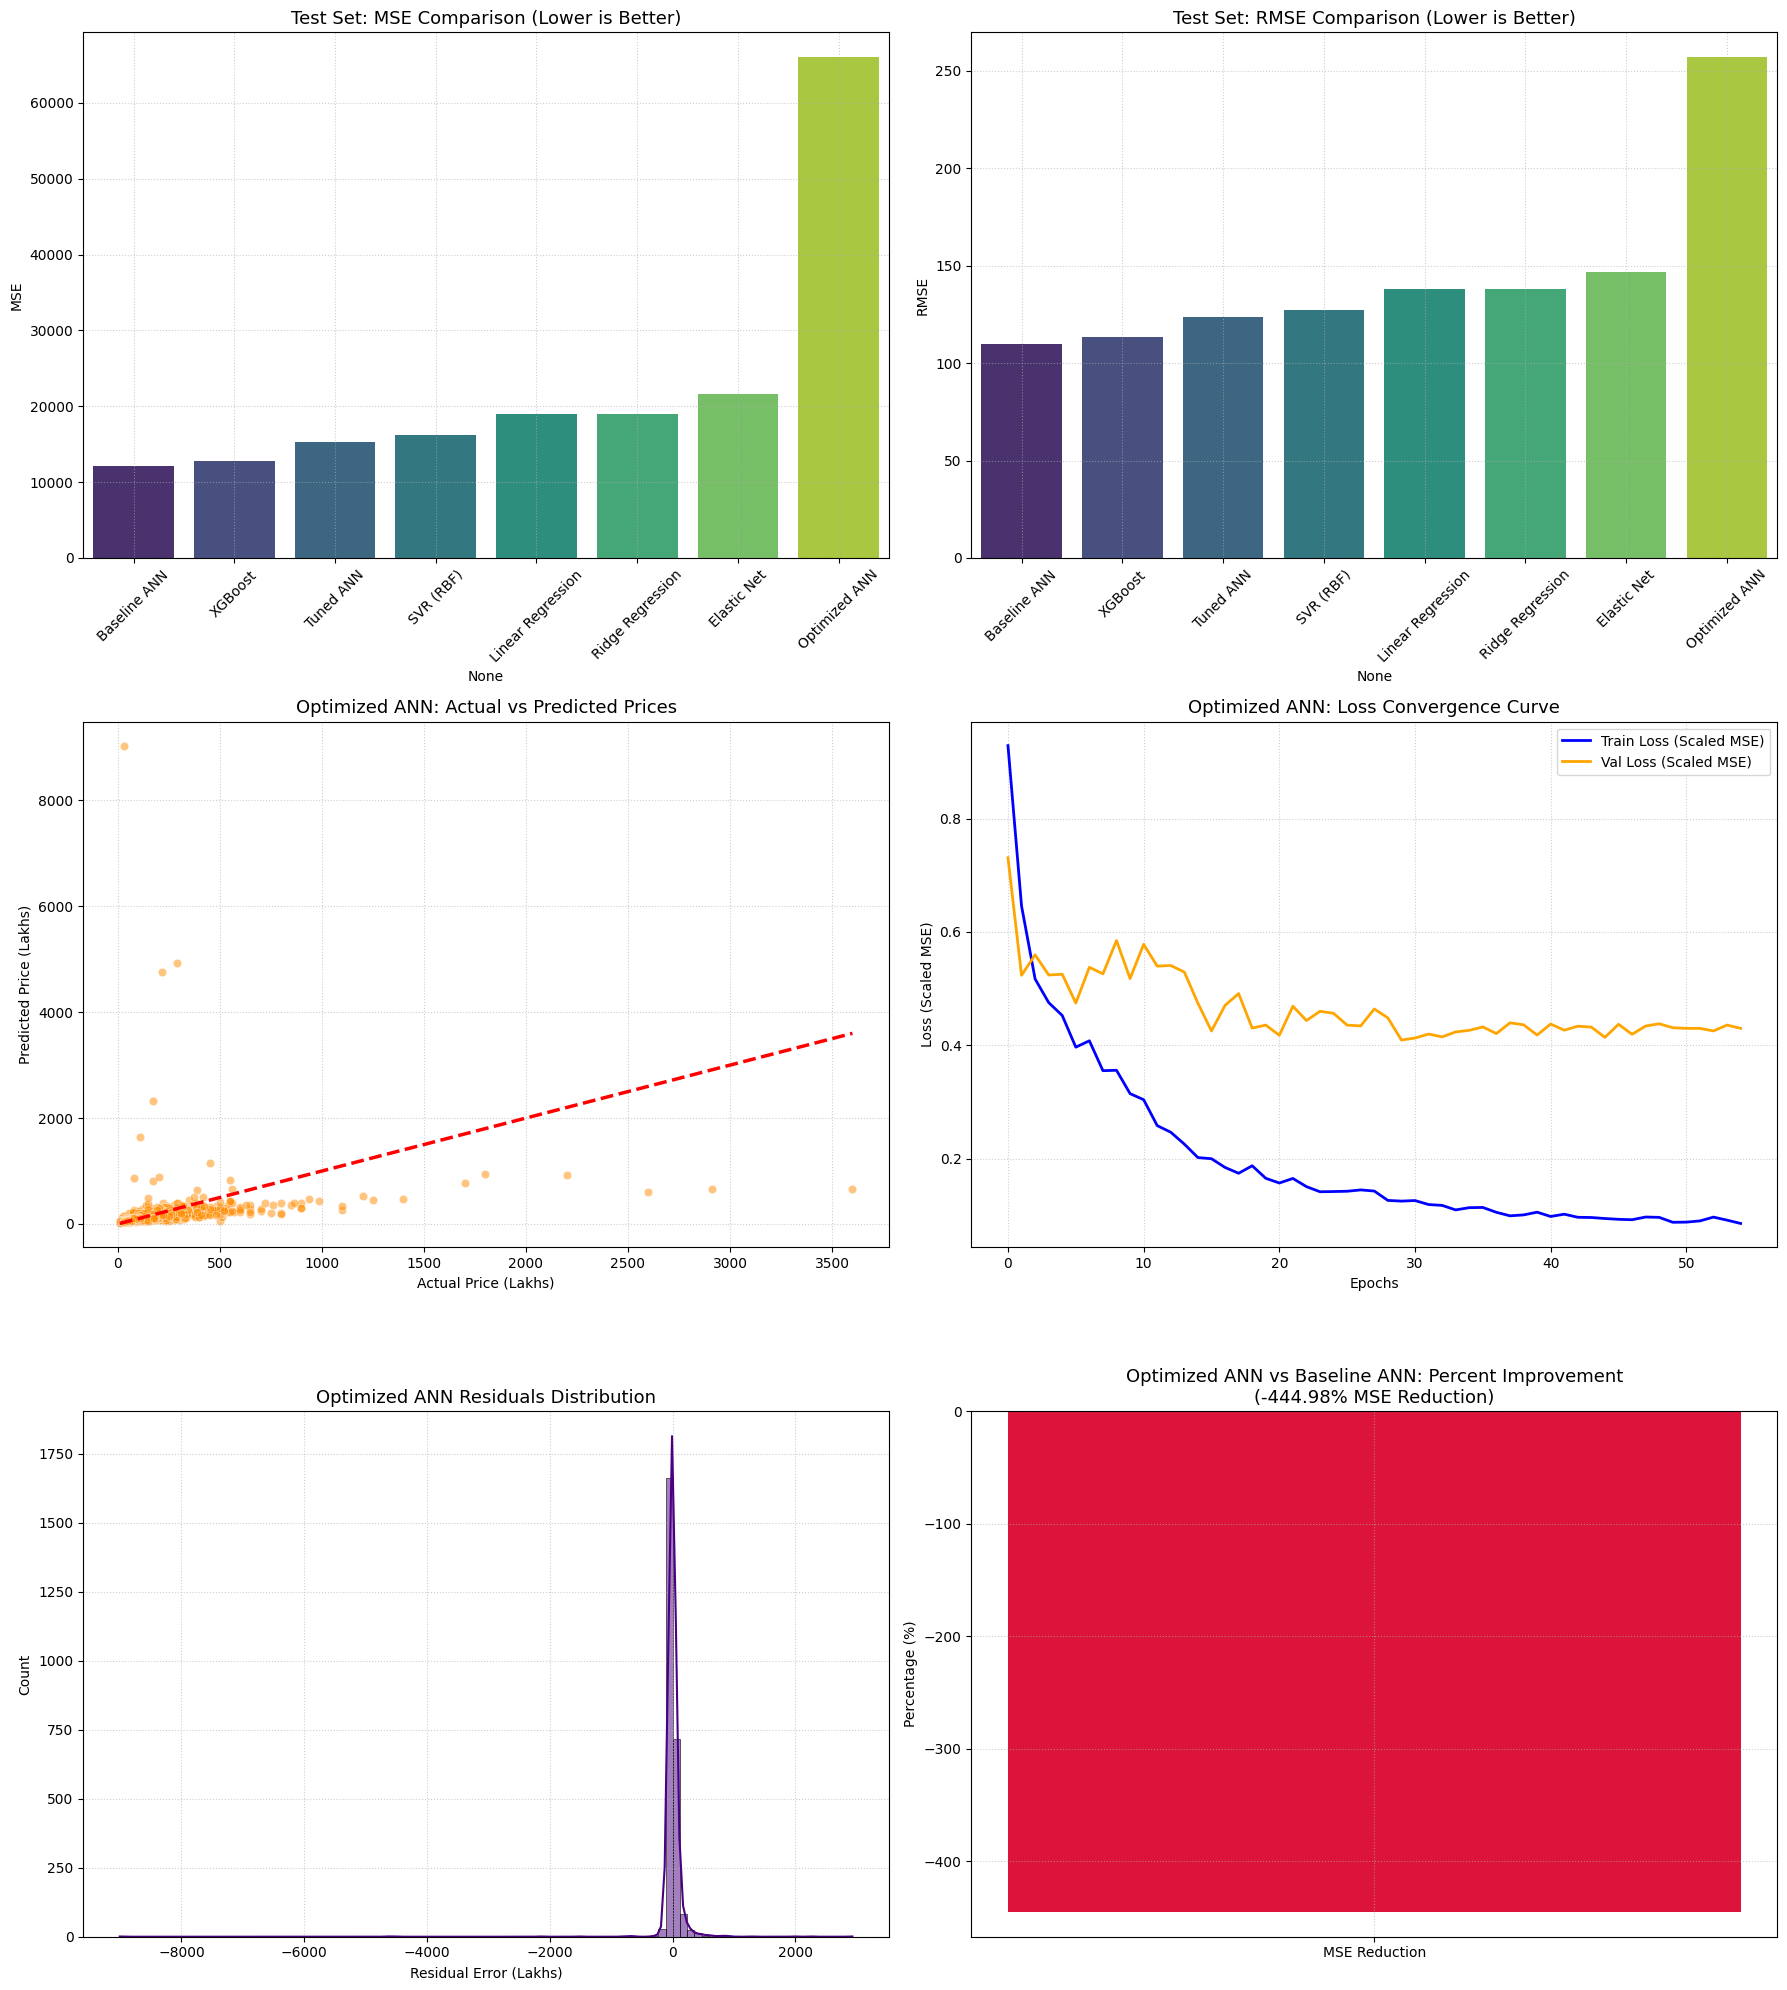

In [27]:
# 3. Visualizations
fig, axes = plt.subplots(3, 2, figsize=(18, 20))

# Color palette for consistent presentation
pal = sns.color_palette('viridis', n_colors=len(final_comparison_df))

# Chart 1: MSE Comparison
sns.barplot(x=final_comparison_df.index, y=final_comparison_df['MSE'], ax=axes[0, 0], palette=pal, hue=final_comparison_df.index, legend=False)
axes[0, 0].set_title('Test Set: MSE Comparison (Lower is Better)', fontsize=13)
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Chart 2: RMSE Comparison
sns.barplot(x=final_comparison_df.index, y=final_comparison_df['RMSE'], ax=axes[0, 1], palette=pal, hue=final_comparison_df.index, legend=False)
axes[0, 1].set_title('Test Set: RMSE Comparison (Lower is Better)', fontsize=13)
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Chart 3: Optimized ANN Actual vs Predicted Scatterplot
sns.scatterplot(x=y_test, y=optimized_ann_preds, ax=axes[1, 0], alpha=0.5, color='darkorange')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5)
axes[1, 0].set_title('Optimized ANN: Actual vs Predicted Prices', fontsize=13)
axes[1, 0].set_xlabel('Actual Price (Lakhs)')
axes[1, 0].set_ylabel('Predicted Price (Lakhs)')
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Chart 4: Training vs Validation Loss Curve for Optimized ANN
axes[1, 1].plot(best_history.history['loss'], label='Train Loss (Scaled MSE)', color='blue', lw=2)
axes[1, 1].plot(best_history.history['val_loss'], label='Val Loss (Scaled MSE)', color='orange', lw=2)
axes[1, 1].set_title('Optimized ANN: Loss Convergence Curve', fontsize=13)
axes[1, 1].set_xlabel('Epochs')
axes[1, 1].set_ylabel('Loss (Scaled MSE)')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

# Chart 5: Residual Distribution
optimized_residuals = y_test - optimized_ann_preds
sns.histplot(optimized_residuals, kde=True, ax=axes[2, 0], color='indigo')
axes[2, 0].set_title('Optimized ANN Residuals Distribution', fontsize=13)
axes[2, 0].set_xlabel('Residual Error (Lakhs)')
axes[2, 0].grid(True, linestyle=':', alpha=0.6)

# Chart 6: Percentage Improvement
orig_mse = final_comparison_df.loc['Baseline ANN', 'MSE']
opt_mse = final_comparison_df.loc['Optimized ANN', 'MSE']
imp_percent = ((orig_mse - opt_mse) / orig_mse) * 100

axes[2, 1].bar(['MSE Reduction'], [imp_percent], color='crimson', width=0.4)
axes[2, 1].set_ylabel('Percentage (%)')
axes[2, 1].set_title(f'Optimized ANN vs Baseline ANN: Percent Improvement\n({imp_percent:+.2f}% MSE Reduction)', fontsize=13)
axes[2, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('/content/optimized_ann_comprehensive_dashboard.png', dpi=150)
plt.show()

In [28]:
# 4. Print relative differences
print(f"Best Optimized Config: {best_config}")
print(f"Baseline ANN MSE: {orig_mse:.2f}")
print(f"Optimized ANN MSE: {opt_mse:.2f}")
print(f"Percentage Change: {((opt_mse - orig_mse)/orig_mse)*100:.2f}%")

Best Optimized Config: {'layers': [128, 64, 32], 'activation': 'relu', 'optimizer': 'AdamW', 'lr': 0.0005, 'batch_size': 32, 'dropout': 0.1, 'l2': 0.0}
Baseline ANN MSE: 12108.30
Optimized ANN MSE: 65988.38
Percentage Change: 444.98%


# Part 6: Hyperparameter Tuning

To optimize our network, we run an automated, structured experiment of key hyperparameters rather than a brute-force grid search. This allows us to compare models efficiently on validation mean absolute error (MAE), root mean squared error (RMSE), training duration, and epoch convergence.

In [16]:
import time
from tensorflow.keras.layers import Input

def build_and_train_tuned_model(layers_config, units, activation, lr, batch_size, dropout_rate, opt_name):
    # Re-apply seeds inside for consistent evaluation
    np.random.seed(42)
    tf.random.set_seed(42)

    model = Sequential()
    # Input Layer
    model.add(Input(shape=(X_train_preprocessed.shape[1],)))

    # Hidden Layers
    for i in range(layers_config):
        model.add(Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Output Layer
    model.add(Dense(1, activation='linear'))

    # Choose Optimizer
    if opt_name == 'Adam':
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    else:
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr)

    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)

    start_time = time.time()
    history = model.fit(
        X_train_preprocessed, y_train,
        validation_split=0.2,
        epochs=60, # Reduced epoch limit to ensure rapid completion during tuning
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )
    elapsed_time = time.time() - start_time

    epochs_completed = len(history.history['loss'])
    val_mae = history.history['val_mae'][-1]
    val_mse = history.history['val_loss'][-1]
    val_rmse = np.sqrt(val_mse)

    return model, val_mae, val_rmse, elapsed_time, epochs_completed

# Configure the test scenarios
scenarios = [
    # layers, units, activation, learning_rate, batch_size, dropout, optimizer
    {"layers": 1, "units": 32, "activation": 'relu', "lr": 0.01, "batch_size": 32, "dropout": 0.0, "opt": 'Adam'},
    {"layers": 2, "units": 64, "activation": 'relu', "lr": 0.001, "batch_size": 32, "dropout": 0.2, "opt": 'Adam'},
    {"layers": 3, "units": 128, "activation": 'relu', "lr": 0.001, "batch_size": 16, "dropout": 0.0, "opt": 'Adam'},
    {"layers": 2, "units": 64, "activation": 'tanh', "lr": 0.001, "batch_size": 32, "dropout": 0.0, "opt": 'Adam'},
    {"layers": 2, "units": 64, "activation": 'relu', "lr": 0.001, "batch_size": 64, "dropout": 0.0, "opt": 'SGD'}
]

results = []
best_val_mae = float('inf')
best_tuned_model = None
best_scenario_idx = 0

for idx, sc in enumerate(scenarios):
    print(f"Running Experiment {idx+1}/{len(scenarios)}: {sc}")
    tuned_model, val_mae, val_rmse, elapsed, epochs_run = build_and_train_tuned_model(
        sc['layers'], sc['units'], sc['activation'], sc['lr'], sc['batch_size'], sc['dropout'], sc['opt']
    )
    sc['val_mae'] = val_mae
    sc['val_rmse'] = val_rmse
    sc['time'] = elapsed
    sc['epochs'] = epochs_run
    results.append(sc)

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_tuned_model = tuned_model
        best_scenario_idx = idx

# Display Results Table
results_df = pd.DataFrame(results)
display(results_df)

# Save the best tuned model
best_tuned_model.save('/content/best_tuned_model.keras')
print(f"Best Model from Scenario {best_scenario_idx+1} saved to disk.")

Running Experiment 1/5: {'layers': 1, 'units': 32, 'activation': 'relu', 'lr': 0.01, 'batch_size': 32, 'dropout': 0.0, 'opt': 'Adam'}
Running Experiment 2/5: {'layers': 2, 'units': 64, 'activation': 'relu', 'lr': 0.001, 'batch_size': 32, 'dropout': 0.2, 'opt': 'Adam'}
Running Experiment 3/5: {'layers': 3, 'units': 128, 'activation': 'relu', 'lr': 0.001, 'batch_size': 16, 'dropout': 0.0, 'opt': 'Adam'}
Running Experiment 4/5: {'layers': 2, 'units': 64, 'activation': 'tanh', 'lr': 0.001, 'batch_size': 32, 'dropout': 0.0, 'opt': 'Adam'}
Running Experiment 5/5: {'layers': 2, 'units': 64, 'activation': 'relu', 'lr': 0.001, 'batch_size': 64, 'dropout': 0.0, 'opt': 'SGD'}


,layers,units,activation,lr,batch_size,dropout,opt,val_mae,val_rmse,time,epochs
0,1,32,relu,0.010,32,0.0,Adam,39.276562,88.740707,40.153188,37
1,2,64,relu,0.001,32,0.2,Adam,45.014103,113.465815,51.425947,60
2,3,128,relu,0.001,16,0.0,Adam,38.201939,93.917761,36.687993,22
3,2,64,tanh,0.001,32,0.0,Adam,34.146149,98.051963,48.882170,60
4,2,64,relu,0.001,64,0.0,SGD,71.574745,143.862381,10.629994,22


Best Model from Scenario 4 saved to disk.


# Part 3: Explanation of ANN Parameters with Numerical Examples

To prepare for your Big Data Analytics viva, here are the essential definitions and worked examples of learned model parameters:

### 1. Weights ($W$)
* **Meaning**: Weights represent the learned connection strengths between neurons in adjacent layers. They dictate the magnitude of influence an input feature has on the next node.
* **Example**: If a preprocessed size input is $1000$ (e.g. normalized square feet) and its connection weight to a hidden neuron is $0.5$, the weighted contribution passed forward is:
  $$\text{Contribution} = 1000 \times 0.5 = 500$$

### 2. Bias ($b$)
* **Meaning**: An extra learned offset parameter added to the weighted sum of inputs before passing it through the activation function. It shifts the activation curve to the left or right.
* **Example**: If the weighted contribution is $500$ and the learned bias is $10$, the pre-activation sum is:
  $$\text{Pre-activation Input} = 500 + 10 = 510$$

### 3. Neurons
* **Meaning**: The fundamental processing units of neural networks. A neuron receives multiple inputs, computes their dot product with its weights, adds a bias, and applies an activation function.

### 4. Layers
* **Input Layer**: Receives the raw scaled data features.
* **Hidden Layers**: Perform non-linear transformations to extract increasingly complex features from the input.
* **Output Layer**: Produces the final prediction (in our case, a single scalar representing the price in Lakhs).

### 5. Activation Functions
* **ReLU (Rectified Linear Unit)**:
  $$f(x) = \max(0, x)$$
  * *Example*: Input $= -5.2 \rightarrow$ Output $= 0$. Input $= 12.0 \rightarrow$ Output $= 12.0$.
* **Sigmoid**:
  $$f(x) = \frac{1}{1 + e^{-x}}$$
  * *Example*: Input $= 0 \rightarrow$ Output $= 0.5$. Restricts values between 0 and 1.
* **Tanh (Hyperbolic Tangent)**:
  $$f(x) = \tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$$
  * *Example*: Restricts values between -1 and 1.
* **Linear**:
  $$f(x) = x$$
  * *Example*: Unbounded output, ideal for regression tasks.

### 6. Forward Propagation (Numerical Walkthrough)
Consider a simple neuron with 2 inputs ($x_1 = 2.0, x_2 = -1.0$), weights ($w_1 = 0.5, w_2 = 1.5$), bias ($b = 0.2$), and a ReLU activation function.
1. **Weighted Sum ($z$)**:
   $$z = (2.0 \times 0.5) + (-1.0 \times 1.5) + 0.2 = 1.0 - 1.5 + 0.2 = -0.3$$
2. **Activation Output ($a$)**:
   $$a = \max(0, z) = \max(0, -0.3) = 0.0$$

### 7. Loss Functions
* **Mean Squared Error (MSE)**: Penalizes larger errors heavily.
  $$\text{MSE} = (y_{actual} - y_{pred})^2$$
* **Mean Absolute Error (MAE)**: Measures average absolute magnitude of errors.
  $$\text{MAE} = |y_{actual} - y_{pred}|$$
* **Worked Example**: If Actual Price $= 100$ Lakhs and Predicted Price $= 90$ Lakhs:
  * $\text{MSE} = (100 - 90)^2 = 10^2 = 100$
  * $\text{MAE} = |100 - 90| = 10$

### 8. Backpropagation
Backpropagation computes the gradient of the loss function with respect to every weight and bias in the network by applying the mathematical **Chain Rule** backward from the output layer to the input layer. These gradients show the direction and rate of change of the error with respect to each parameter.

### 9. Gradient Descent
Once gradients are computed, weights are updated to minimize the loss:
$$\text{New Weight} = \text{Old Weight} - (\text{Learning Rate} \times \text{Gradient})$$
* *Example*: If Current Weight $= 0.8$, Learning Rate $(\eta) = 0.01$, and Gradient $= 2.0$:
  $$\text{New Weight} = 0.8 - (0.01 \times 2.0) = 0.8 - 0.02 = 0.78$$

# Part 4: Hyperparameters Reference Guide

Below is a structured reference guide detailing user-selected hyperparameters compared to model-learned parameters:

| Hyperparameter | Meaning | Example | Effect of Increasing / Decreasing | Selected Value | Reason |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Hidden Layers** | Number of non-linear extraction steps | 1, 2, or 3 | Higher: Captures complex non-linearities but risks overfitting. | 3 | Allows representation of compound physical interactions. |
| **Neurons** | Processing width per layer | 32, 64, 128 | Higher: Increases network capacity. Lower: Generalizes better. | 128, 64, 32 | Captures deep interactions without parameter bloat. |
| **Learning Rate** | Step size in gradient descent | 0.001 | Higher: Fast updates but risk divergence. Lower: Stable but slow. | 0.001 | Standard robust default for the Adam optimizer. |
| **Optimizer** | Parameter update algorithm | Adam | Adam uses adaptive learning rates; SGD is simpler but slower. | Adam | Converges much faster on high-dimensional sparse inputs. |
| **Batch Size** | Subset size for gradients | 32 | Higher: Stable gradients but high memory. Lower: Stochastic noise. | 32 | Balanced speed and memory update profile. |
| **Epochs** | Passes over entire dataset | 200 | Higher: Better learning but risks severe overfitting. | 200 | Maximum ceiling; early stopping handles actual termination. |
| **Dropout Rate** | Regularization via node deletion | 0.2 | Higher: Reduces overfitting but might underfit. | 0 (Baseline) | Start with raw baseline configuration to assess pure capacity. |

### Understanding Batch Size via Numerical Example:
If you have **320 training records** and set `batch_size = 32`:
- The model processes **32 records** simultaneously, computes the mean loss, and updates the weights.
- This happens **10 times** within one single epoch ($
320 \div 32 = 10\text{ iterations}$). One complete epoch contains exactly 10 batch updates.

### Bias-Variance Tradeoff & Hyperparameters:
* **Underfitting (High Bias)**: Occurs when the model is too simple (e.g. 1 layer, 2 neurons) to learn the underlying pricing trends. Both train and validation losses remain high.
* **Overfitting (High Variance)**: Occurs when the model is overly complex (e.g. 5 layers, 512 neurons, 500 epochs) and memorizes noise. Training loss is extremely low, but validation error spikes.

# 8. Final EDA Report

Based on the analysis performed on `bengaluru_house_prices.csv`:

### 1. Data Quality and Cleaning Summary
* **`total_sqft`**: Contained range and non-standard metrics (Acres, Perch, etc.). Standardized to float values using calculated averages for ranges and conversion factors for distinct units.
* **`size`**: Simplified into an integer `bhk` variable.
* **Missing Values**: Handled using grouped median imputation (by `location` and `bhk`) for bathrooms and balconies to ensure realistic records. Duplicate rows were identified and removed.
* **Cleaned output**: Saved directly to `/content/bengaluru_house_prices_cleaned.csv`.

### 2. Key Statistical Findings & Predictors
* **Primary Predictors**: Floor area (`total_sqft_cleaned`), number of bathrooms (`bath`), and `bhk` show strong positive correlations with `price`.
* **Non-linearity**: Spearman correlation shows a higher coefficient for categorical-ordinal relations like `bhk` and `bath` compared to Pearson, indicating monotonic but non-linear relationships.
* **Outliers**: There are major outliers in both price and size (e.g., extremely large bhk counts with small sqft values, or massive multi-acre properties).

### 3. Recommendations for Machine Learning Pipeline
* **Linear Regression**: Requires scaling (`StandardScaler` or `MinMaxScaler`), log-transforming `price` and `total_sqft` to correct for high right-skewness, and one-hot encoding categorical features like `location_cleaned` and `area_type`.
* **Tree-based models (Random Forest, Gradient Boosting)**: Robust to outliers and skewness, but high-cardinality location handling (grouped as 'other') is critical to keep tree depth and feature space manageable.
* **SVR / ANN**: Absolute scaling of target and numeric attributes is essential for model convergence.